✅ Input CSV file 'input_files.csv' created.

✅ Loaded: 30C_AfterActivation_07152025.csv
✅ Loaded: 50C_AfterActivation_07152025.csv
✅ Loaded: 30C_Recovery_AfterActivation_07152025.csv


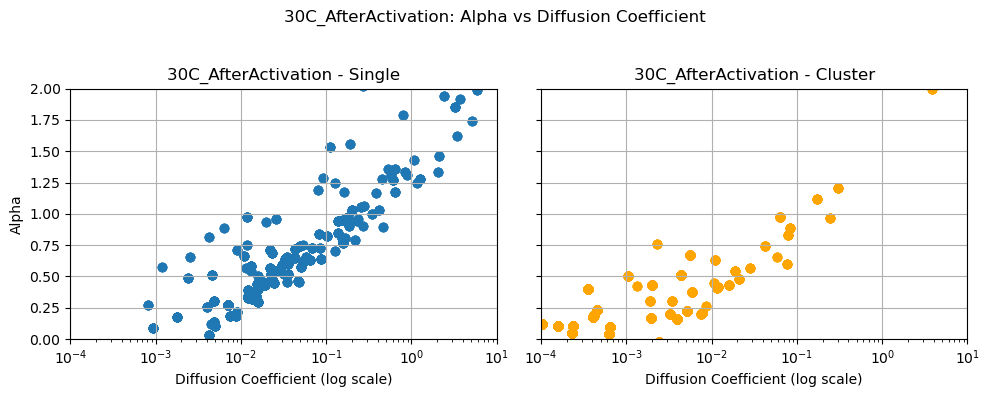

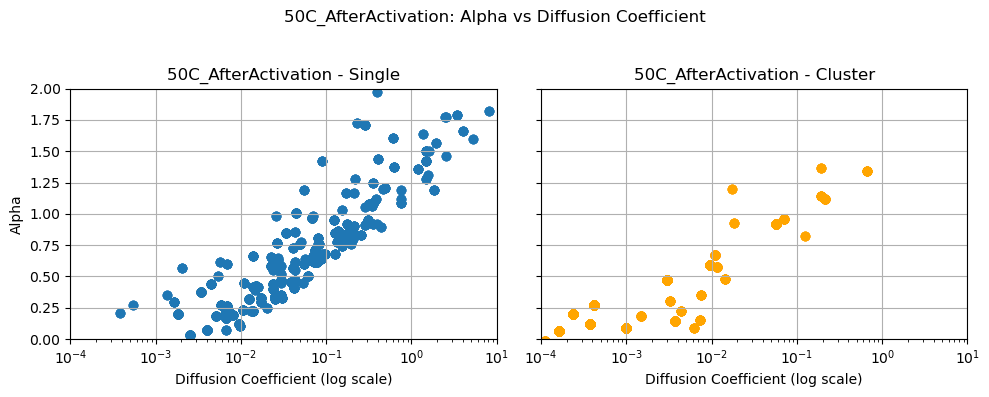

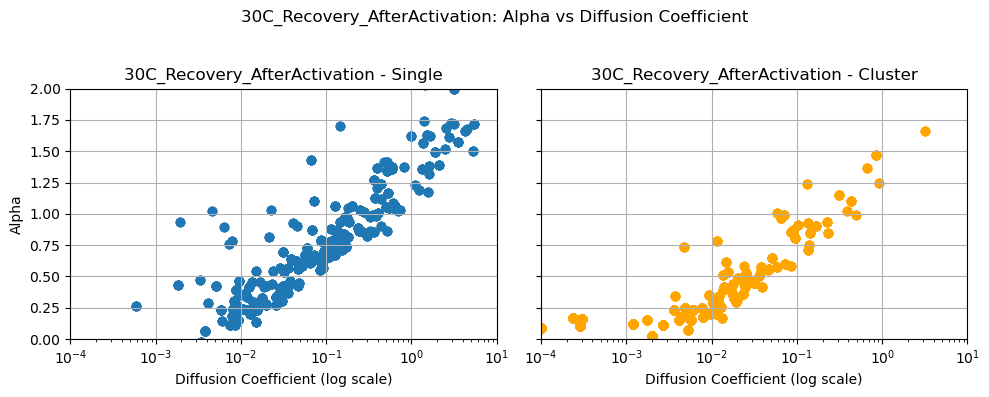

In [2]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from sklearn.neighbors import KernelDensity
from scipy.optimize import curve_fit
from matplotlib import gridspec

# Step 1: Optional input file writer
def create_input_csv():
    with open("input_files.csv", "w") as f:
        f.write("""category,filepath
30C_AfterActivation,30C_AfterActivation_07152025.csv

50C_AfterActivation,50C_AfterActivation_07152025.csv

30C_Recovery_AfterActivation,30C_Recovery_AfterActivation_07152025.csv

""")
    print("✅ Input CSV file 'input_files.csv' created.\n")
    
def load_grouped_csvs(input_csv_path):
    input_df = pd.read_csv(input_csv_path)
    grouped_data = {
        "30C_AfterActivation": [],
        "50C_AfterActivation": [],
        "30C_Recovery_AfterActivation": []
    }

    for _, row in input_df.iterrows():
        category = row['category']
        filepath = row['filepath']
        if category in grouped_data:
            try:
                df = pd.read_csv(filepath)
                df.attrs["filepath"] = filepath  # ✅ Attach source file path here
                grouped_data[category].append(df)
                print(f"✅ Loaded: {filepath}")
            except Exception as e:
                print(f"❌ Failed to load {filepath}: {e}")
    return grouped_data

# Step 2: Loader function
# def load_grouped_csvs(input_csv_path):
#     input_df = pd.read_csv(input_csv_path)
#     grouped_data = { "30C_AfterActivation": [], "40C_AfterActivation": [], "50C_AfterActivation": [], "30C_Recovery_AfterActivation": [] }

#     for _, row in input_df.iterrows():
#         category = row['category']
#         filepath = row['filepath']
#         if category in grouped_data:
#             try:
#                 df = pd.read_csv(filepath)
#                 grouped_data[category].append(df)
#                 print(f"✅ Successfully loaded: {os.path.basename(filepath)}")
#             except Exception as e:
#                 print(f"❌ Failed to load {filepath}: {e}")
#         else:
#             print(f"⚠️ Ignored unknown category: {category}")
#     return grouped_data

# Step 3: Plotting function with log x-axis, axis limits, and per-plot grid
def plot_alpha_vs_D_separate(grouped_data):
    for category, dfs in grouped_data.items():
        if dfs:
            combined_df = pd.concat(dfs, ignore_index=True)

            required_columns = ['alpha', 'Diffusion Coefficient', 'classification']
            if not all(col in combined_df.columns for col in required_columns):
                print(f"⚠️ Missing required columns in group: {category}")
                continue

            # Filter single and cluster
            single_df = combined_df[combined_df['classification'].str.lower() == 'single molecule']
            cluster_df = combined_df[combined_df['classification'].str.lower() == 'cluster']

            fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

            # Plot single molecule
            if not single_df.empty:
                axes[0].scatter(single_df['Diffusion Coefficient'], single_df['alpha'], alpha=0.7)
                axes[0].set_xscale('log')
                axes[0].set_xlim(1e-4, 10)
                axes[0].set_ylim(0, 2)
                axes[0].set_xlabel("Diffusion Coefficient (log scale)")
                axes[0].set_ylabel("Alpha")
                axes[0].set_title(f"{category} - Single")
                axes[0].grid(True)

            # Plot cluster
            if not cluster_df.empty:
                axes[1].scatter(cluster_df['Diffusion Coefficient'], cluster_df['alpha'], alpha=0.7, color='orange')
                axes[1].set_xscale('log')
                axes[1].set_xlim(1e-4, 10)
                axes[1].set_ylim(0, 2)
                axes[1].set_xlabel("Diffusion Coefficient (log scale)")
                axes[1].set_title(f"{category} - Cluster")
                axes[1].grid(True)

            # Overall layout
            plt.suptitle(f"{category}: Alpha vs Diffusion Coefficient", fontsize=12)
            plt.tight_layout(rect=[0, 0, 1, 0.95])
            plt.show()

# Step 4: Run everything
if __name__ == "__main__":
    create_input_csv()
    grouped_data = load_grouped_csvs("input_files.csv")
    plot_alpha_vs_D_separate(grouped_data)


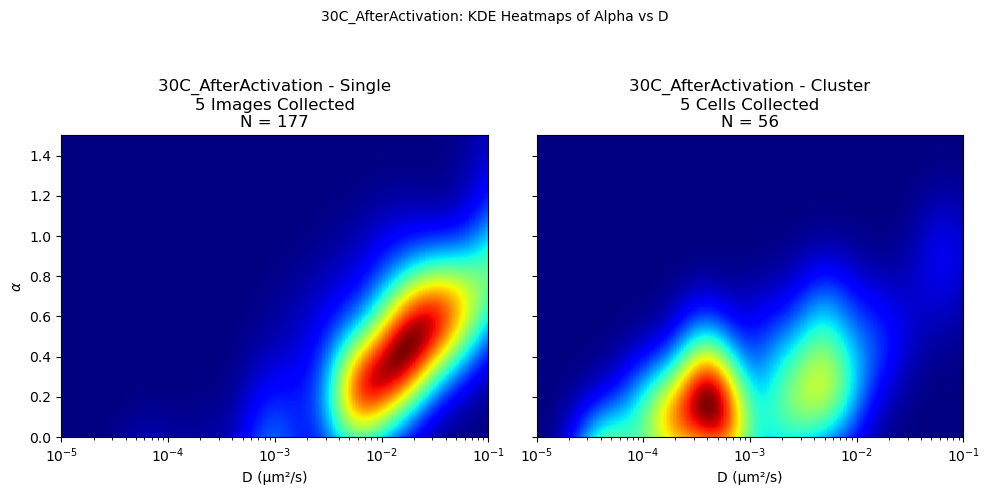

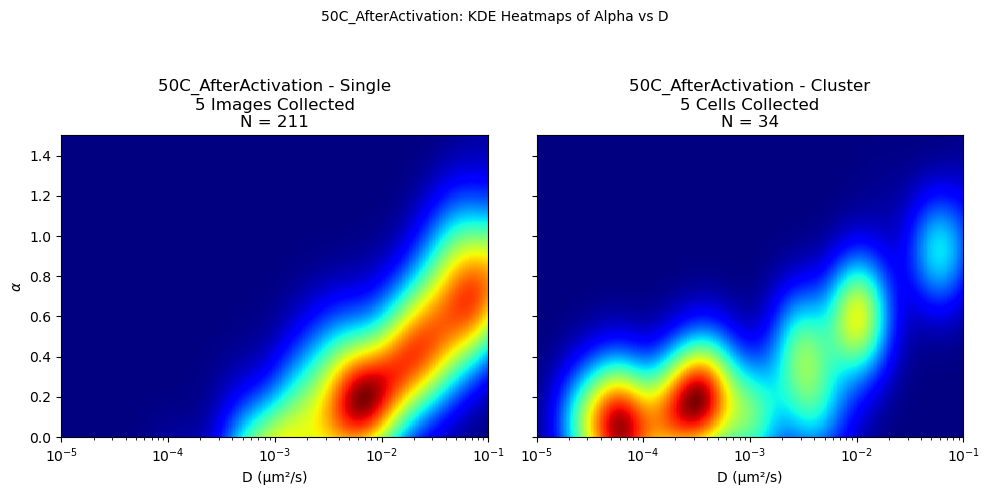

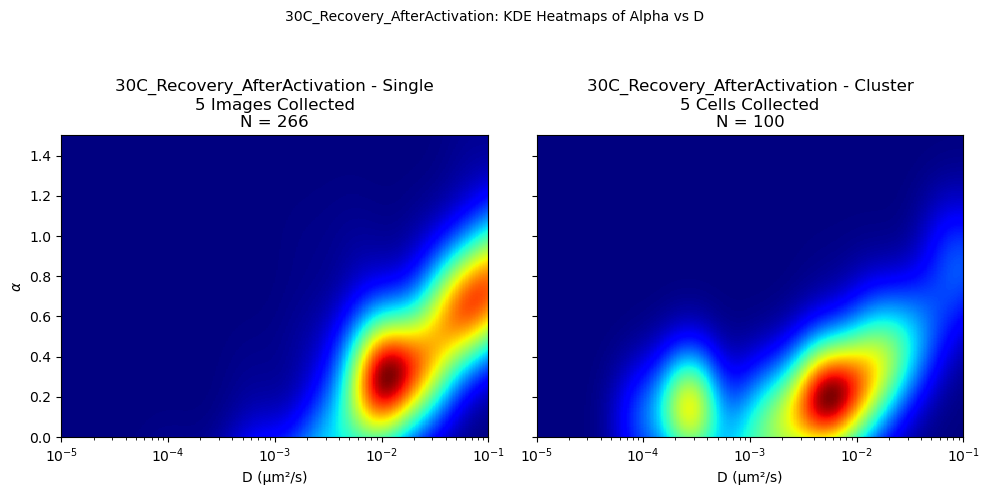

In [3]:
def compute_2D_KDE(data_x, data_y, grid_x, grid_y, bandwidth):
    kde = KernelDensity(kernel='gaussian', bandwidth=bandwidth)
    points = np.vstack([data_x, data_y]).T
    kde.fit(points)
    grid_coords = np.vstack([grid_x.ravel(), grid_y.ravel()]).T
    log_density = kde.score_samples(grid_coords)
    density = np.exp(log_density).reshape(grid_x.shape)
    density /= density.max()
    return density

def plot_kde_heatmaps(grouped_data, bandwidth=0.2):
    D_min, D_max = 1e-5, 1e-1
    alpha_min, alpha_max = 0, 1.5

    for category, dfs in grouped_data.items():
        if not dfs:
            continue

        df = pd.concat(dfs, ignore_index=True)
        required_cols = ['alpha', 'Diffusion Coefficient', 'classification', 'particle']
        if not all(col in df.columns for col in required_cols):
            print(f"⚠️ Missing required columns in group: {category}")
            continue

        single = df[df['classification'].str.lower() == 'single molecule'].dropna(subset=['alpha', 'Diffusion Coefficient', 'particle'])
        cluster = df[df['classification'].str.lower() == 'cluster'].dropna(subset=['alpha', 'Diffusion Coefficient', 'particle'])

        fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharey=True)

        # Grid
        D_grid = np.logspace(np.log10(D_min), np.log10(D_max), 300)
        alpha_grid = np.linspace(alpha_min, alpha_max, 300)
        grid_x, grid_y = np.meshgrid(D_grid, alpha_grid)

        if not single.empty:
            density = compute_2D_KDE(np.log10(single['Diffusion Coefficient']), single['alpha'], np.log10(grid_x), grid_y, bandwidth)
            axes[0].pcolormesh(grid_x, grid_y, density, shading='auto', cmap=plt.cm.jet, norm=Normalize(vmin=0, vmax=1))
            axes[0].set_xscale('log')
            axes[0].set_xlim(D_min, D_max)
            axes[0].set_ylim(alpha_min, alpha_max)
            axes[0].set_xlabel('D (μm²/s)')
            axes[0].set_ylabel(r'$\alpha$')
            n_unique_single = single['particle'].nunique()
            axes[0].set_title(f"{category} - Single\n5 Images Collected\nN = {n_unique_single}")
            axes[0].grid(False)

        if not cluster.empty:
            density = compute_2D_KDE(np.log10(cluster['Diffusion Coefficient']), cluster['alpha'], np.log10(grid_x), grid_y, bandwidth)
            axes[1].pcolormesh(grid_x, grid_y, density, shading='auto', cmap=plt.cm.jet, norm=Normalize(vmin=0, vmax=1))
            axes[1].set_xscale('log')
            axes[1].set_xlim(D_min, D_max)
            axes[1].set_ylim(alpha_min, alpha_max)
            axes[1].set_xlabel('D (μm²/s)')
            n_unique_cluster = cluster['particle'].nunique()
            axes[1].set_title(f"{category} - Cluster\n5 Cells Collected\nN = {n_unique_cluster}")
            axes[1].grid(False)

        plt.suptitle(f"{category}: KDE Heatmaps of Alpha vs D", fontsize=10)
        plt.tight_layout(rect=[0, 0, 1, 0.93])
        plt.show()
#Call
plot_kde_heatmaps(grouped_data, bandwidth=0.2)


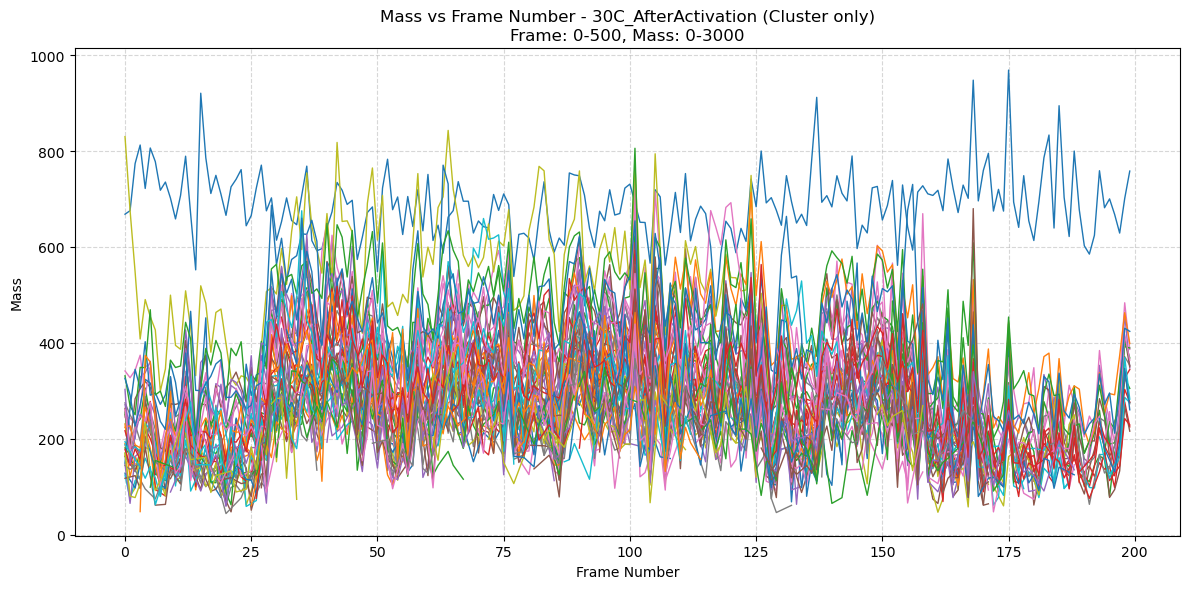

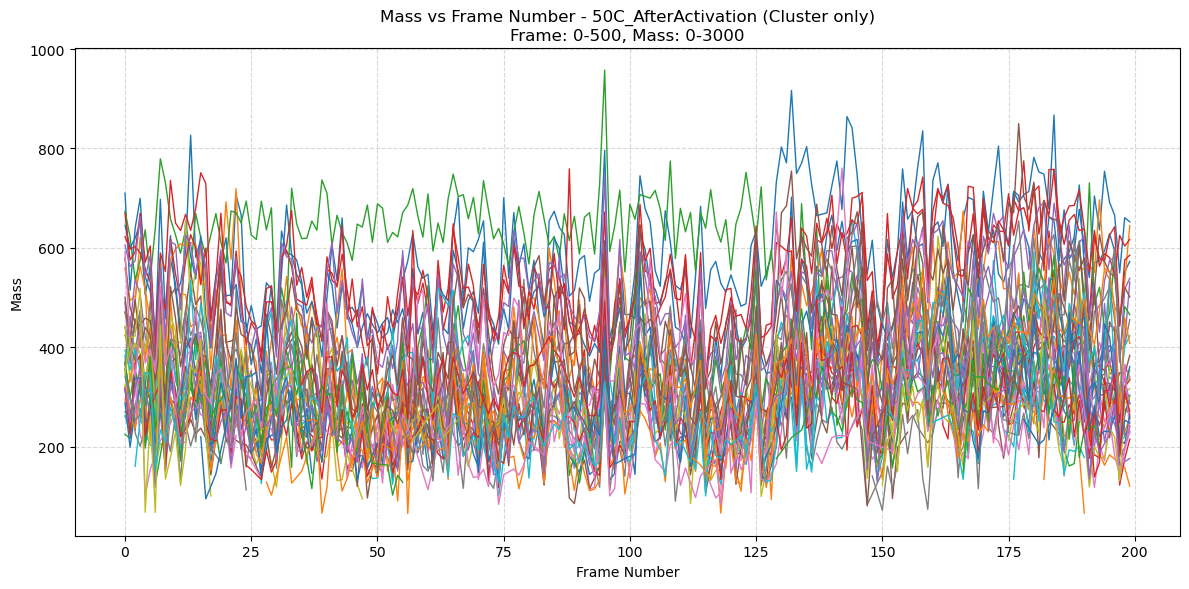

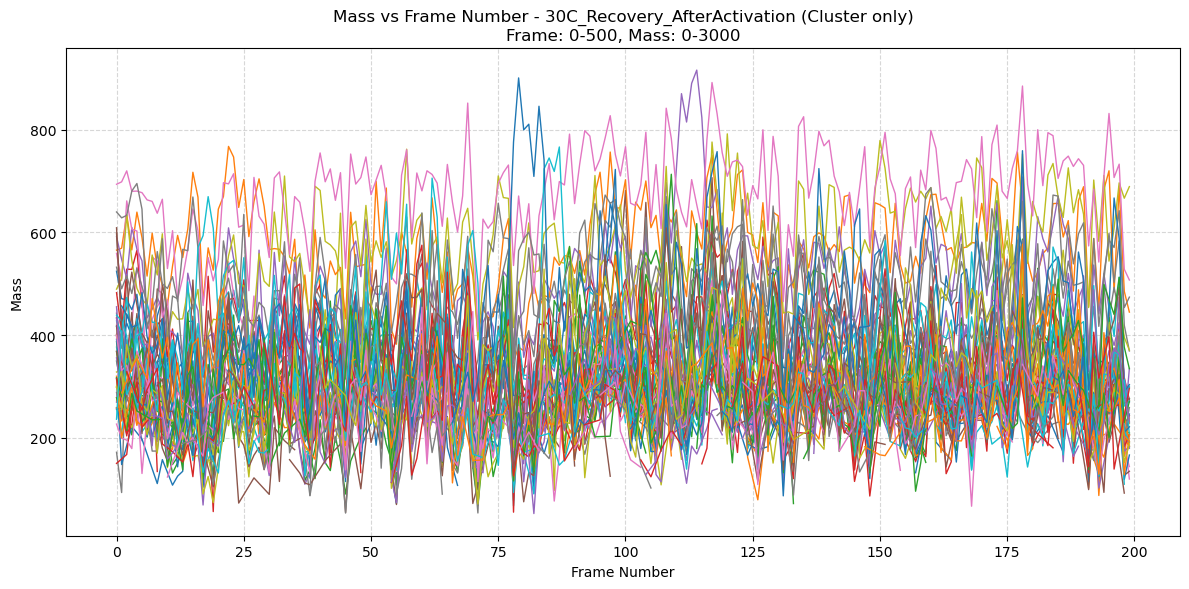

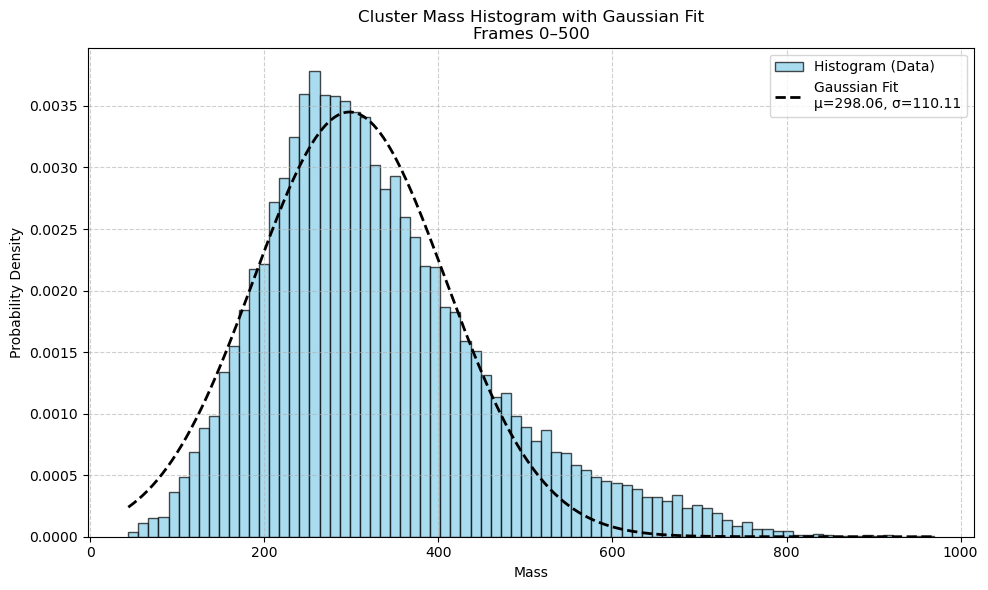

✅ Gaussian Fit Parameters:
  Mean (μ): 298.06
  Std Dev (σ): 110.11
⚠️ No cluster mass data found in specified frame range.


In [4]:
# === CONFIGURATION ===
start_frame = 0
end_frame = 500
min_mass = 0
max_mass = 3000

# Store all cluster mass values
all_cluster_masses = []

# === Gaussian Fit Function ===
def gaussian(x, amp, mean, sigma):
    return amp * np.exp(-0.5 * ((x - mean) / sigma) ** 2)

# === Main plotting function ===
def plot_mass_vs_frame_per_group(grouped_data, start_frame, end_frame, min_mass, max_mass):
    global all_cluster_masses

    for group_name, dfs in grouped_data.items():
        if not dfs:
            print(f"⚠️ No data for group: {group_name}")
            continue

        particle_offset = 0
        adjusted_dfs = []

        for df in dfs:
            if not all(col in df.columns for col in ['frame', 'mass', 'particle', 'classification']):
                print(f"⚠️ Skipping a file in {group_name}: missing required columns.")
                continue

            df = df.copy()
            df['particle'] += particle_offset
            particle_offset = df['particle'].max() + 1
            adjusted_dfs.append(df)

        if not adjusted_dfs:
            print(f"⚠️ No usable data in group: {group_name}")
            continue

        combined_df = pd.concat(adjusted_dfs, ignore_index=True)

        # Filter for clusters and frame/mass range
        cluster_df = combined_df[combined_df['classification'].str.lower() == 'cluster']
        filtered_df = cluster_df[
            (cluster_df['frame'] >= start_frame) &
            (cluster_df['frame'] <= end_frame) &
            (cluster_df['mass'] >= min_mass) &
            (cluster_df['mass'] <= max_mass)
        ]

        # Collect all mass values
        all_cluster_masses.extend(filtered_df['mass'].dropna().values)

        if filtered_df.empty:
            print(f"ℹ️ No cluster data in {group_name} within specified filters.")
            continue

        # Plot individual particle mass traces
        plt.figure(figsize=(12, 6))
        for particle_id, group in filtered_df.groupby('particle'):
            plt.plot(group['frame'], group['mass'], linewidth=1)

        plt.title(f"Mass vs Frame Number - {group_name} (Cluster only)\n"
                  f"Frame: {start_frame}-{end_frame}, Mass: {min_mass}-{max_mass}")
        plt.xlabel('Frame Number')
        plt.ylabel('Mass')
        plt.grid(True, linestyle='--', alpha=0.5)
        plt.tight_layout()
        plt.show()

# === Single Gaussian Function ===
def gaussian(x, amp, mean, sigma):
    return amp * np.exp(-0.5 * ((x - mean) / sigma) ** 2)

# === Histogram and Gaussian Fit for Cluster Masses ===
def plot_cluster_mass_histogram(grouped_data, start_frame=0, end_frame=500):
    all_cluster_masses = []

    for dfs in grouped_data.values():
        for df in dfs:
            if not all(col in df.columns for col in ['mass', 'classification', 'frame']):
                continue
            clusters = df[
                (df['classification'].str.lower() == 'cluster') &
                (df['frame'] >= start_frame) &
                (df['frame'] <= end_frame)
            ]
            masses = clusters['mass'].dropna()
            all_cluster_masses.extend(masses.values)

    if not all_cluster_masses:
        print("⚠️ No cluster mass data found in specified frame range.")
        return

    mass_data = np.array(all_cluster_masses)
    hist, bins = np.histogram(mass_data, bins=40, density=True)
    bin_centers = (bins[:-1] + bins[1:]) / 2

    mean_est = mass_data.mean()
    std_est = mass_data.std()
    amp_est = hist.max()

    try:
        popt, _ = curve_fit(gaussian, bin_centers, hist, p0=[amp_est, mean_est, std_est])
        amp, mean, sigma = popt
    except RuntimeError:
        print("⚠️ Gaussian fit failed.")
        return

    # Plot histogram and fit
    plt.figure(figsize=(10, 6))
    plt.hist(mass_data, bins=80, density=True, color='skyblue', edgecolor='black', alpha=0.7, label='Histogram (Data)')
    x_fit = np.linspace(min(mass_data), max(mass_data), 500)
    plt.plot(x_fit, gaussian(x_fit, *popt), 'k--', linewidth=2, label=f'Gaussian Fit\nμ={mean:.2f}, σ={sigma:.2f}')

    plt.xlabel('Mass')
    plt.ylabel('Probability Density')
    plt.title(f'Cluster Mass Histogram with Gaussian Fit\nFrames {start_frame}–{end_frame}')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()

    print(f"✅ Gaussian Fit Parameters:\n  Mean (μ): {mean:.2f}\n  Std Dev (σ): {sigma:.2f}")


# === Run plotting and histogram ===
plot_mass_vs_frame_per_group(grouped_data, start_frame, end_frame, min_mass, max_mass)
plot_cluster_mass_histogram(grouped_data)
plot_cluster_mass_histogram(grouped_data, start_frame=300, end_frame=500)


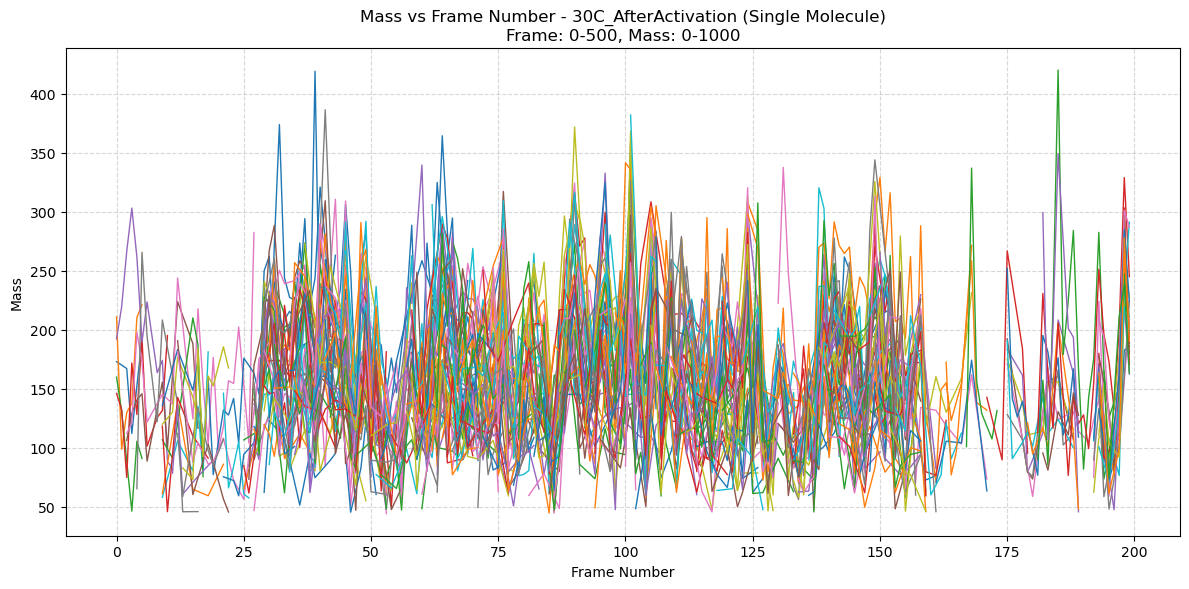

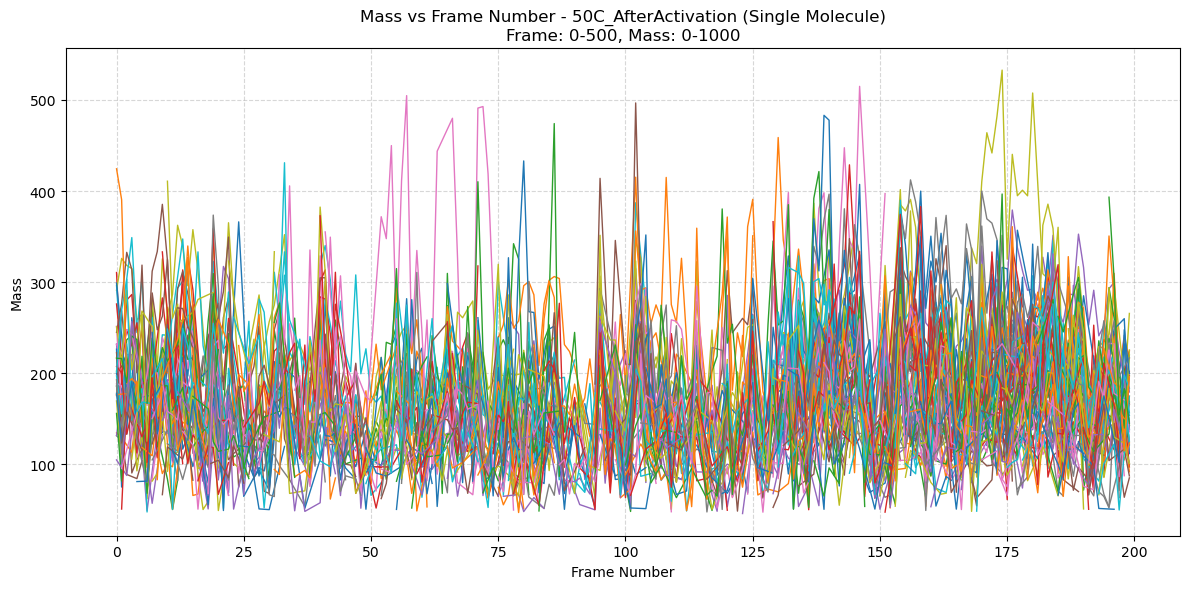

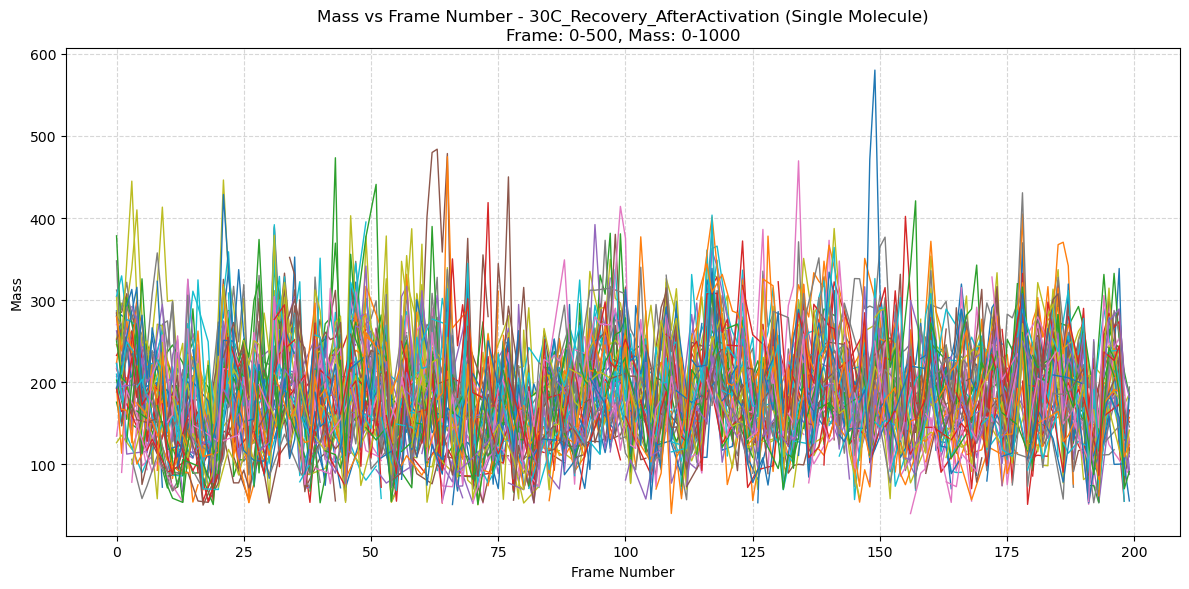

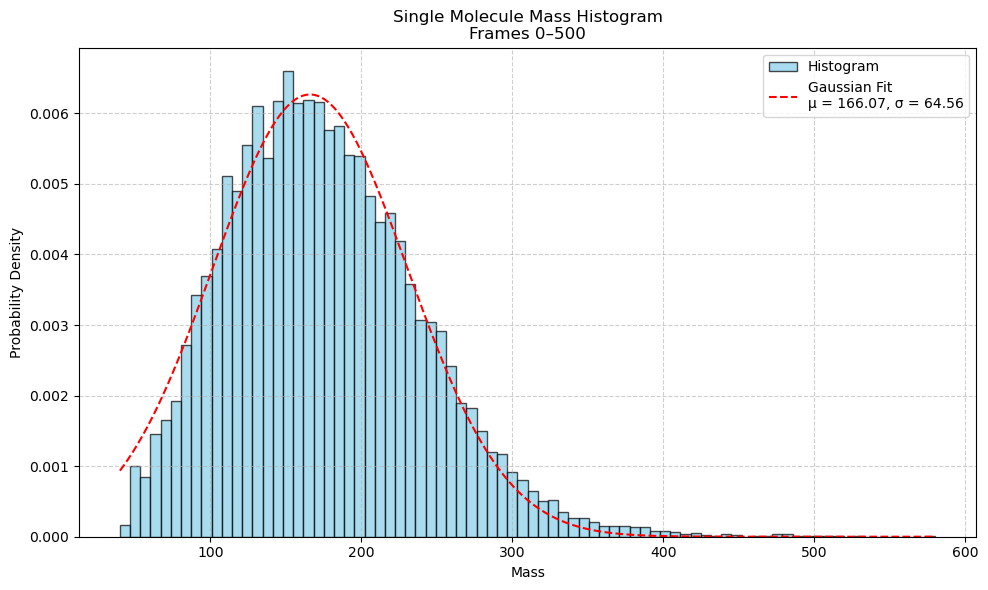

⚠️ No mass data found for single molecules in specified frame range.


In [5]:
# === CONFIGURATION ===
start_frame = 0       # Minimum frame to consider
end_frame = 500       # Maximum frame to consider
min_mass = 0          # Minimum mass to consider
max_mass = 1000       # Maximum mass to consider

# === Main plotting function for Single Molecules ===
def plot_mass_vs_frame_per_group_SM(grouped_data, start_frame, end_frame, min_mass, max_mass):
    for group_name, dfs in grouped_data.items():
        if not dfs:
            print(f"⚠️ No data for group: {group_name}")
            continue

        particle_offset = 0
        adjusted_dfs = []

        # Ensure particle IDs are unique across all files in the group
        for df in dfs:
            if not all(col in df.columns for col in ['frame', 'mass', 'particle', 'classification']):
                print(f"⚠️ Skipping a file in {group_name}: missing required columns.")
                continue

            df = df.copy()
            df['particle'] += particle_offset
            particle_offset = df['particle'].max() + 1
            adjusted_dfs.append(df)

        if not adjusted_dfs:
            print(f"⚠️ No usable data in group: {group_name}")
            continue

        combined_df = pd.concat(adjusted_dfs, ignore_index=True)

        # Filter for single molecule classification and frame/mass range
        sm_df = combined_df[combined_df['classification'].str.lower() == 'single molecule']
        filtered_df = sm_df[
            (sm_df['frame'] >= start_frame) &
            (sm_df['frame'] <= end_frame) &
            (sm_df['mass'] >= min_mass) &
            (sm_df['mass'] <= max_mass)
        ]

        if filtered_df.empty:
            print(f"ℹ️ No single molecule data in {group_name} within specified filters.")
            continue

        # Plot each particle trace
        plt.figure(figsize=(12, 6))
        for particle_id, group in filtered_df.groupby('particle'):
            plt.plot(group['frame'], group['mass'], linewidth=1)

        plt.title(f"Mass vs Frame Number - {group_name} (Single Molecule)\n"
                  f"Frame: {start_frame}-{end_frame}, Mass: {min_mass}-{max_mass}")
        plt.xlabel('Frame Number')
        plt.ylabel('Mass')
        plt.grid(True, linestyle='--', alpha=0.5)
        plt.tight_layout()
        plt.show()

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# === Single Gaussian Function ===
def single_gaussian(x, amp, mean, sigma):
    return amp * np.exp(-0.5 * ((x - mean) / sigma) ** 2)

# === Plot Histogram with Single Gaussian Fit for SM Mass ===
def plot_sm_mass_histogram(grouped_data, start_frame=0, end_frame=500):
    all_masses = []

    for dfs in grouped_data.values():
        for df in dfs:
            if not all(col in df.columns for col in ['mass', 'classification', 'frame']):
                continue
            sm = df[
                (df['classification'].str.lower() == 'single molecule') &
                (df['frame'] >= start_frame) &
                (df['frame'] <= end_frame)
            ]
            masses = sm['mass'].dropna()
            all_masses.extend(masses.values)

    if not all_masses:
        print("⚠️ No mass data found for single molecules in specified frame range.")
        return

    data = np.array(all_masses)

    # Histogram and Fit Setup
    hist, bins = np.histogram(data, bins=40, density=True)
    bin_centers = (bins[:-1] + bins[1:]) / 2
    mean_guess = data.mean()
    std_guess = data.std()
    amp_guess = max(hist)
    p0 = [amp_guess, mean_guess, std_guess]

    try:
        popt, _ = curve_fit(single_gaussian, bin_centers, hist, p0=p0)
    except RuntimeError:
        print("❌ Gaussian fit failed.")
        return

    amp, mean, sigma = popt

    # Plotting
    plt.figure(figsize=(10, 6))
    plt.hist(data, bins=80, density=True, color='skyblue', edgecolor='black', alpha=0.7, label="Histogram")
    x_fit = np.linspace(min(data), max(data), 1000)
    y_fit = single_gaussian(x_fit, *popt)
    plt.plot(x_fit, y_fit, 'r--', label=f'Gaussian Fit\nμ = {mean:.2f}, σ = {sigma:.2f}')
    plt.xlabel('Mass')
    plt.ylabel('Probability Density')
    plt.title(f'Single Molecule Mass Histogram\nFrames {start_frame}–{end_frame}')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()


plot_mass_vs_frame_per_group_SM(grouped_data, start_frame, end_frame, min_mass, max_mass)
plot_sm_mass_histogram(grouped_data)
plot_sm_mass_histogram(grouped_data, start_frame=300, end_frame=500)

/var/folders/0k/3k6whtl53gzbzkn6wq663f5c0000gn/T/ipykernel_82973/3982859476.py:4: RuntimeWarning: divide by zero encountered in divide
  g2 = amp2 * np.exp(-0.5 * ((x - mean2) / sigma2) ** 2)
/var/folders/0k/3k6whtl53gzbzkn6wq663f5c0000gn/T/ipykernel_82973/3982859476.py:3: RuntimeWarning: divide by zero encountered in divide
  g1 = amp1 * np.exp(-0.5 * ((x - mean1) / sigma1) ** 2)


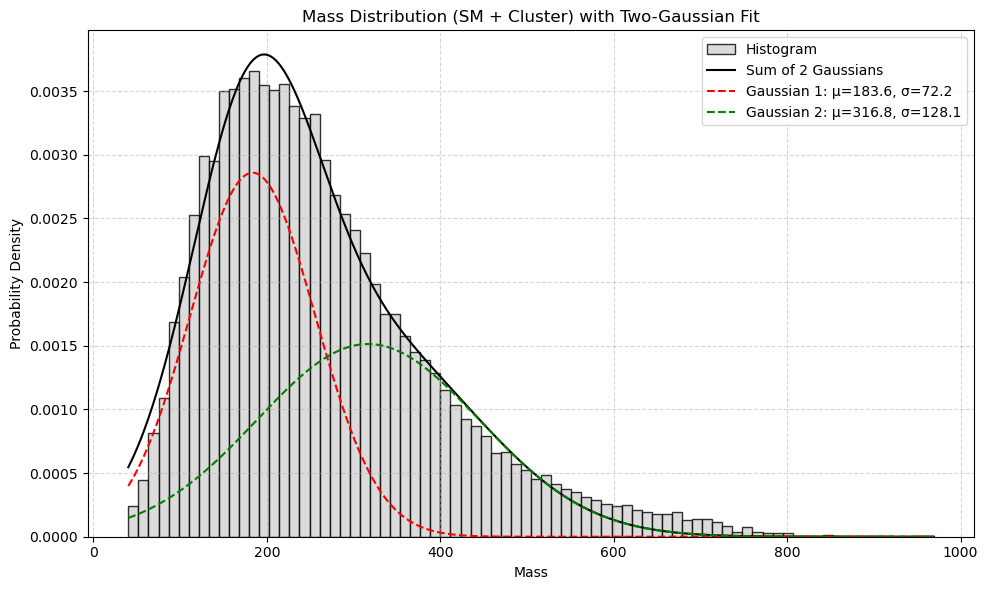

In [6]:
# === Define the sum of two Gaussian functions ===
def double_gaussian(x, amp1, mean1, sigma1, amp2, mean2, sigma2):
    g1 = amp1 * np.exp(-0.5 * ((x - mean1) / sigma1) ** 2)
    g2 = amp2 * np.exp(-0.5 * ((x - mean2) / sigma2) ** 2)
    return g1 + g2

# === Combined histogram + Gaussian fit ===
def plot_combined_mass_histogram(grouped_data):
    all_masses = []

    for dfs in grouped_data.values():
        for df in dfs:
            if 'mass' not in df.columns or 'classification' not in df.columns:
                continue

            sm_data = df[df['classification'].str.lower() == 'single molecule']['mass'].dropna().values
            cluster_data = df[df['classification'].str.lower() == 'cluster']['mass'].dropna().values

            all_masses.extend(sm_data)
            all_masses.extend(cluster_data)

    if not all_masses:
        print("⚠️ No mass data available.")
        return

    data = np.array(all_masses)

    # Create histogram
    hist, bins = np.histogram(data, bins=60, density=True)
    bin_centers = (bins[:-1] + bins[1:]) / 2

    # Initial guess
    mean = data.mean()
    std = data.std()
    p0 = [max(hist), mean * 0.7, std * 0.5,
          max(hist) * 0.6, mean * 1.3, std]

    # Fit
    try:
        popt, _ = curve_fit(double_gaussian, bin_centers, hist, p0=p0)
    except RuntimeError:
        print("❌ Gaussian fitting failed.")
        return

    amp1, mean1, sigma1, amp2, mean2, sigma2 = popt

    # Plot
    plt.figure(figsize=(10, 6))
    plt.hist(data, bins=80, density=True, color='lightgray', edgecolor='black', alpha=0.8, label='Histogram')
    x_fit = np.linspace(min(data), max(data), 1000)
    y_fit = double_gaussian(x_fit, *popt)
    plt.plot(x_fit, y_fit, 'k-', label='Sum of 2 Gaussians')
    plt.plot(x_fit, double_gaussian(x_fit, amp1, mean1, sigma1, 0, 0, 0), 'r--',
             label=f'Gaussian 1: μ={mean1:.1f}, σ={sigma1:.1f}')
    plt.plot(x_fit, double_gaussian(x_fit, 0, 0, 0, amp2, mean2, sigma2), 'g--',
             label=f'Gaussian 2: μ={mean2:.1f}, σ={sigma2:.1f}')

    plt.xlabel('Mass')
    plt.ylabel('Probability Density')
    plt.title('Mass Distribution (SM + Cluster) with Two-Gaussian Fit')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

# === Run the plot ===
plot_combined_mass_histogram(grouped_data)


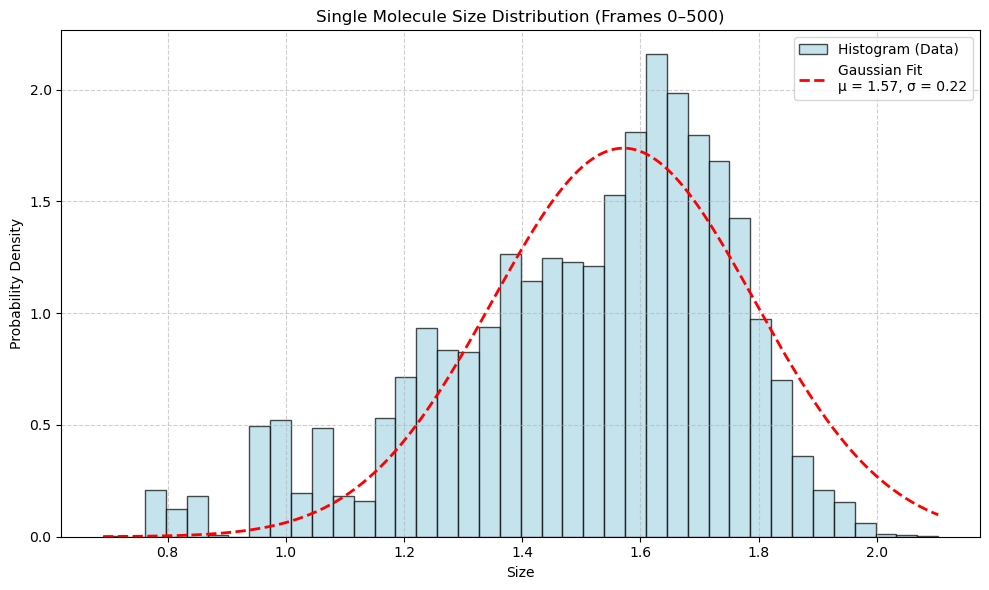

✅ Single Molecule Size Distribution Gaussian Fit:
  Mean (μ): 1.57
  Std Dev (σ): 0.22


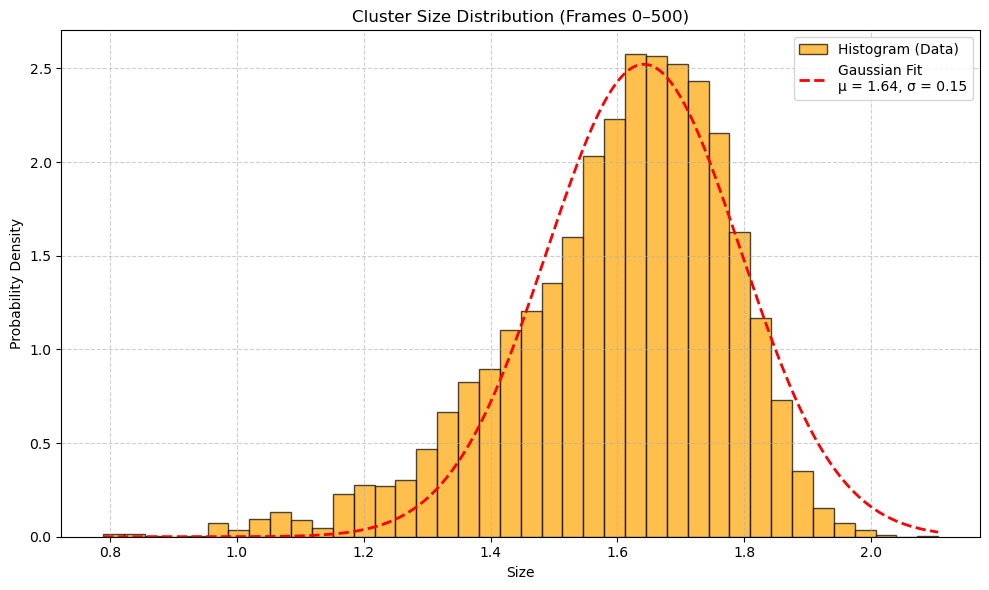

✅ Cluster Size Distribution Gaussian Fit:
  Mean (μ): 1.64
  Std Dev (σ): 0.15
⚠️ No size data available for: Single Molecule Size Distribution
⚠️ No size data available for: Cluster Size Distribution


In [7]:
# Gaussian model
def gaussian(x, amp, mean, sigma):
    return amp * np.exp(-0.5 * ((x - mean) / sigma) ** 2)

# Plot SM and Cluster size histograms with Gaussian fit
def plot_size_histograms_sm_and_cluster(grouped_data, start_frame=0, end_frame=500):
    sm_sizes = []
    cluster_sizes = []

    for dfs in grouped_data.values():
        for df in dfs:
            if not all(col in df.columns for col in ['size', 'classification', 'frame']):
                continue
            df = df[(df['frame'] >= start_frame) & (df['frame'] <= end_frame)]

            sm = df[df['classification'].str.lower() == 'single molecule']['size'].dropna()
            cluster = df[df['classification'].str.lower() == 'cluster']['size'].dropna()

            sm_sizes.extend(sm.values)
            cluster_sizes.extend(cluster.values)

    def plot_hist_with_fit(data, title, color):
        if len(data) == 0:
            print(f"⚠️ No size data available for: {title}")
            return

        hist, bins = np.histogram(data, bins=40, density=True)
        bin_centers = (bins[:-1] + bins[1:]) / 2
        mean_est = np.mean(data)
        std_est = np.std(data)
        amp_est = hist.max()

        try:
            popt, _ = curve_fit(gaussian, bin_centers, hist, p0=[amp_est, mean_est, std_est])
            amp, mean, sigma = popt
        except RuntimeError:
            print(f"❌ Gaussian fit failed for {title}")
            return

        plt.figure(figsize=(10, 6))
        plt.hist(data, bins=40, density=True, color=color, edgecolor='black', alpha=0.7, label='Histogram (Data)')
        x_fit = np.linspace(min(data), max(data), 500)
        plt.plot(x_fit, gaussian(x_fit, *popt), 'r--', linewidth=2, label=f'Gaussian Fit\nμ = {mean:.2f}, σ = {sigma:.2f}')
        plt.xlabel('Size')
        plt.ylabel('Probability Density')
        plt.title(f'{title} (Frames {start_frame}–{end_frame})')
        plt.legend()
        plt.grid(True, linestyle='--', alpha=0.6)
        plt.tight_layout()
        plt.show()

        print(f"✅ {title} Gaussian Fit:\n  Mean (μ): {mean:.2f}\n  Std Dev (σ): {sigma:.2f}")

    # Plot for Single Molecule
    plot_hist_with_fit(sm_sizes, "Single Molecule Size Distribution", "lightblue")

    # Plot for Cluster
    plot_hist_with_fit(cluster_sizes, "Cluster Size Distribution", "orange")
plot_size_histograms_sm_and_cluster(grouped_data)  # default 0–500
plot_size_histograms_sm_and_cluster(grouped_data, start_frame=300, end_frame=500)

In [26]:
# Constants
mobility_output_csv_path = "Particle_Mobility_Analysis.csv"
cluster_threshold = 1  # Same for all
sm = 3
# Define per-category SM thresholds
sm_thresholds = {
    "30C_AfterActivation": sm,
    "30C_Recovery_AfterActivation": sm,
    "50C_AfterActivation": sm
}

# Initialize results list
mobility_records = []

# Loop through grouped data
for category, dfs in grouped_data.items():
    sm_threshold = sm_thresholds.get(category, 2.3)  # default if not found

    for df in dfs:
        required_columns = {'frame', 'x', 'y', 'particle', 'classification', 'Diffusion Coefficient', 'alpha'}
        if not required_columns.issubset(df.columns):
            continue

        original_file = df.attrs.get("filepath", "Unknown_File")

        for particle_id, group in df.groupby('particle'):
            group = group.sort_values('frame')
            x0, y0 = group.iloc[0][['x', 'y']]
            distances = np.sqrt((group['x'] - x0)**2 + (group['y'] - y0)**2)
            max_distance = distances.max()

            classification = group['classification'].iloc[0].lower()
            polarity = ""
            mobility = ""

            if classification == 'single molecule':
                polarity = "polar" if max_distance < sm_threshold else "nonpolar"
            elif classification == 'cluster':
                mobility = "polar" if max_distance < cluster_threshold else "nonpolar"

            diffusion = group['Diffusion Coefficient'].iloc[0]
            alpha = group['alpha'].iloc[0]

            mobility_records.append({
                "Category": category,
                "File Name": original_file,
                "Particle ID": particle_id,
                "Greatest Distance": max_distance,
                "Classification": classification,
                "SM Polarity": polarity,
                "Cluster Mobility": mobility,
                "Diffusion Coefficient": diffusion,
                "Alpha": alpha
            })

# Save and summarize (same as before)
mobility_df = pd.DataFrame(mobility_records)
mobility_df.to_csv(mobility_output_csv_path, index=False)

# Summary for SM polarity
sm_summary = (
    mobility_df[mobility_df['Classification'] == 'single molecule']
    .groupby(['Category', 'SM Polarity'])
    .size()
    .unstack(fill_value=0)
    .reset_index()
    .rename(columns={'polar': 'SM Polar Count', 'nonpolar': 'SM Nonpolar Count'})
)

# Summary for cluster mobility
cluster_summary = (
    mobility_df[mobility_df['Classification'] == 'cluster']
    .groupby(['Category', 'Cluster Mobility'])
    .size()
    .unstack(fill_value=0)
    .reset_index()
    .rename(columns={'polar': 'Cluster Polar Count', 'nonpolar': 'Cluster Nonpolar Count'})
)

# Merge summaries
final_summary = pd.merge(sm_summary, cluster_summary, on='Category', how='outer').fillna(0)

# Print result
print("\n=== Summary of Particle Mobility ===")
print(final_summary)


# from shapely.geometry import Point, Polygon
# import pandas as pd

# # Load ROI files again (adjust path if necessary)
# roi_30C = pd.read_csv("30C_ROI_Coordinates.csv")
# roi_50C = pd.read_csv("50C_ROI_Coordinates.csv")
# roi_30C_recovery = pd.read_csv("30C_Recovery_ROI_Coordinates.csv")

# # Create expanded ROI polygons
# roi_margin = 0.5  # pixels
# roi_polygons = {
#     "30C_AfterActivation.csv": Polygon(roi_30C[['X', 'Y']].values).buffer(roi_margin),
#     "50C_AfterActivation.csv": Polygon(roi_50C[['X', 'Y']].values).buffer(roi_margin),
#     "30C_Recovery_AfterActivation.csv": Polygon(roi_30C_recovery[['X', 'Y']].values).buffer(roi_margin)
# }


# # Process only available category
# for category, dfs in grouped_data.items():
#     if not dfs:
#         continue

#     for df in dfs:
#         required_columns = {'frame', 'x', 'y', 'particle', 'classification', 'Diffusion Coefficient', 'alpha'}
#         if not required_columns.issubset(df.columns):
#             continue

#         original_file = df.attrs.get("filepath", "Unknown_File")

#         for particle_id, group in df.groupby('particle'):
#             group = group.sort_values('frame')
#             initial = group.iloc[0]
#             point = Point(initial['x'], initial['y'])

#             classification = initial['classification'].lower()
#             polarity = ""
#             mobility = ""

#             # Polarity based on ROI margin check
#             roi_polygon = roi_polygons.get(f"{category}.csv")
#             if roi_polygon is None:
#                 continue
#             inside_roi = roi_polygon.contains(point)


#             if classification == 'single molecule':
#                 polarity = "polar" if inside_roi else "nonpolar"
#             elif classification == 'cluster':
#                 mobility = "polar" if inside_roi else "nonpolar"

#             diffusion = group['Diffusion Coefficient'].iloc[0]
#             alpha = group['alpha'].iloc[0]

#             mobility_records_roi_based.append({
#                 "Category": category,
#                 "File Name": original_file,
#                 "Particle ID": particle_id,
#                 "Initial X": initial['x'],
#                 "Initial Y": initial['y'],
#                 "Frame": initial['frame'],
#                 "Classification": classification,
#                 "SM Polarity": polarity,
#                 "Cluster Mobility": mobility,
#                 "Diffusion Coefficient": diffusion,
#                 "Alpha": alpha
#             })

# # Convert to DataFrame
# mobility_df_roi = pd.DataFrame(mobility_records_roi_based)

# # Save
# output_path = "Particle_Mobility_Analysis_ROI.csv"
# mobility_df_roi.to_csv(output_path, index=False)
# output_path



=== Summary of Particle Mobility ===
                       Category  SM Nonpolar Count  SM Polar Count  \
0           30C_AfterActivation                266             117   
1  30C_Recovery_AfterActivation                448              97   
2           50C_AfterActivation                374              89   

   Cluster Nonpolar Count  Cluster Polar Count  
0                      91                   10  
1                     183                    2  
2                      69                    6  


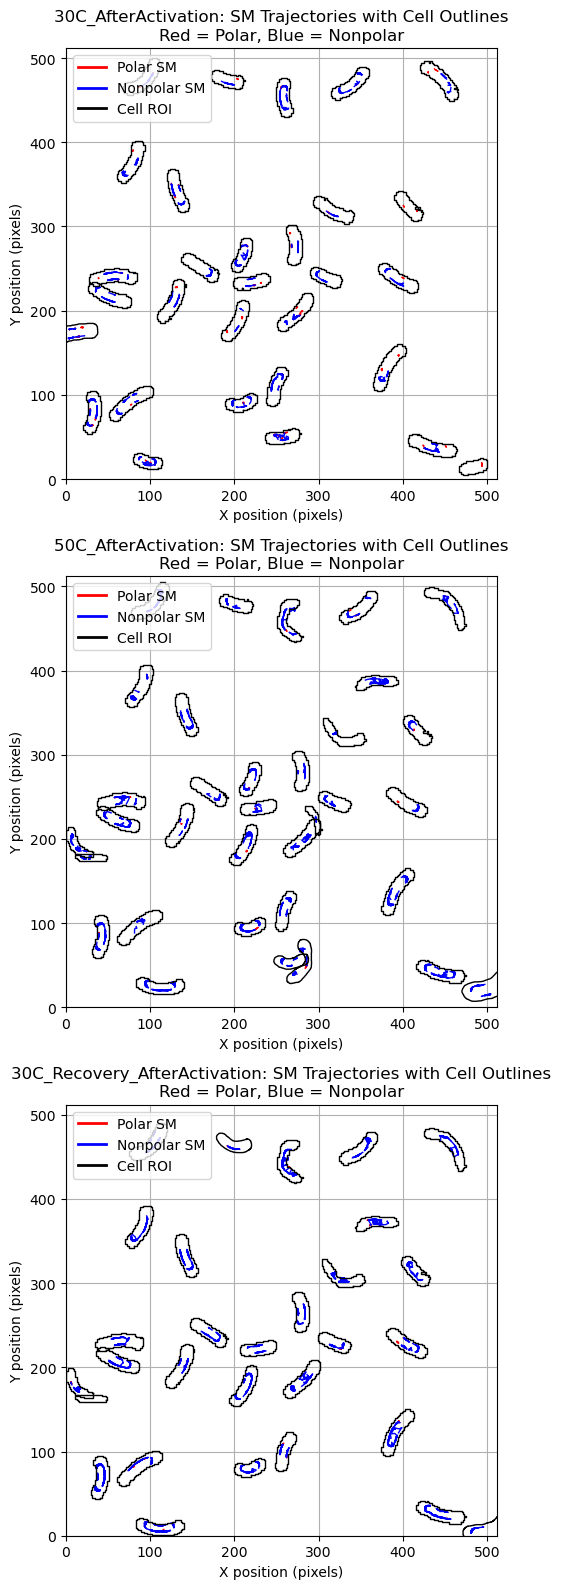

In [27]:
# import matplotlib.pyplot as plt
# from matplotlib.lines import Line2D

# # Use the new ROI-based mobility classification
# #mobility_df = mobility_df_roi.copy()

# # Identify all unique categories (filenames)
# categories = mobility_df[
#     (mobility_df["Classification"] == "single molecule")
# ]["Category"].unique()

# # Plot for each category
# fig, axes = plt.subplots(nrows=len(categories), figsize=(10, 6 * len(categories)))

# if len(categories) == 1:
#     axes = [axes]

# for ax, category in zip(axes, categories):
#     traj_file_path = f"{category.replace('.csv', '')}_07152025.csv"
#     try:
#         traj_df = pd.read_csv(traj_file_path)
#     except FileNotFoundError:
#         print(f"❌ File not found: {traj_file_path}")
#         continue

#     # Get updated polarity info from ROI-based data
#     sm_info = mobility_df[
#         (mobility_df["Category"] == category) &
#         (mobility_df["Classification"] == "single molecule")
#     ]
#     polar_ids = sm_info[sm_info["SM Polarity"] == "polar"]["Particle ID"].unique()
#     nonpolar_ids = sm_info[sm_info["SM Polarity"] == "nonpolar"]["Particle ID"].unique()

#     polar_df = traj_df[traj_df["particle"].isin(polar_ids)]
#     nonpolar_df = traj_df[traj_df["particle"].isin(nonpolar_ids)]

#     # Plot
#     for _, group in polar_df.groupby("particle"):
#         group = group.sort_values("frame")
#         ax.plot(group["x"], group["y"], color='red', linewidth=1, alpha=0.7)

#     for _, group in nonpolar_df.groupby("particle"):
#         group = group.sort_values("frame")
#         ax.plot(group["x"], group["y"], color='blue', linewidth=1, alpha=0.7)

#     ax.set_title(f"Single Molecule Trajectories in {category}\nRed = Polar (ROI), Blue = Nonpolar")
#     ax.set_xlabel("X position (pixels)")
#     ax.set_ylabel("Y position (pixels)")
#     ax.legend(handles=[
#         Line2D([0], [0], color='red', lw=2, label='Polar SM'),
#         Line2D([0], [0], color='blue', lw=2, label='Nonpolar SM')
#     ])
#     ax.grid(True)

# plt.tight_layout()
# plt.show()

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from matplotlib.lines import Line2D

# === CONFIG ===
roi_files = {
    "30C_AfterActivation": "30C_ROI_Coordinates.csv",
    "50C_AfterActivation": "50C_ROI_Coordinates.csv",
    "30C_Recovery_AfterActivation": "30C_Recovery_ROI_Coordinates.csv",
}
trajectory_files = {
    "30C_AfterActivation": "30C_AfterActivation_07152025.csv",
    "50C_AfterActivation": "50C_AfterActivation_07152025.csv",
    "30C_Recovery_AfterActivation": "30C_Recovery_AfterActivation_07152025.csv",
}
mobility_csv = "Particle_Mobility_Analysis.csv"
canvas_size = (512, 512)  # image_shape: (height, width)

# === FUNCTION: Create ROI mask and outline ===
def create_roi_polygons(roi_df, scale_factor=1.3):
    roi_polygons = []
    for label in roi_df['Label'].unique():
        coords = roi_df[roi_df['Label'] == label]
        x = coords['X'].values
        y = coords['Y'].values

        if len(x) < 3:
            continue  # Skip incomplete shapes

        # Compute centroid
        cx, cy = np.mean(x), np.mean(y)

        # Scale points outward from centroid
        scaled_polygon = [((px - cx) * scale_factor + cx, (py - cy) * scale_factor + cy) for px, py in zip(x, y)]
        roi_polygons.append(scaled_polygon)

    return roi_polygons


# === Load mobility data ===
mobility_df = pd.read_csv(mobility_csv)

# === PLOT LOOP ===
fig, axes = plt.subplots(nrows=3, figsize=(10, 16))

for ax, category in zip(axes, roi_files.keys()):
    # --- Load data ---
    roi_df = pd.read_csv(roi_files[category])
    traj_df = pd.read_csv(trajectory_files[category])

    polar_ids = mobility_df[(mobility_df['Category'] == category) & 
                            (mobility_df['Classification'] == 'single molecule') & 
                            (mobility_df['SM Polarity'] == 'polar')]['Particle ID'].unique()

    nonpolar_ids = mobility_df[(mobility_df['Category'] == category) & 
                                (mobility_df['Classification'] == 'single molecule') & 
                                (mobility_df['SM Polarity'] == 'nonpolar')]['Particle ID'].unique()

    polar_df = traj_df[traj_df["particle"].isin(polar_ids)]
    nonpolar_df = traj_df[traj_df["particle"].isin(nonpolar_ids)]

    # --- Plot Trajectories ---
    for _, group in polar_df.groupby("particle"):
        group = group.sort_values("frame")
        ax.plot(group["x"], group["y"], color='red', linewidth=1)

    for _, group in nonpolar_df.groupby("particle"):
        group = group.sort_values("frame")
        ax.plot(group["x"], group["y"], color='blue', linewidth=1)

    # --- Plot ROI Outlines ---
    roi_polygons = create_roi_polygons(roi_df, scale_factor=1.5)  # or 1.5 for more enlargement

    for polygon in roi_polygons:
        x, y = zip(*polygon)
        x = list(x) + [x[0]]  # close loop
        y = list(y) + [y[0]]
        ax.plot(x, y, color='black', linewidth=1)

    # --- Final plot settings ---
    ax.set_title(f"{category}: SM Trajectories with Cell Outlines\nRed = Polar, Blue = Nonpolar")
    ax.set_xlim(0, canvas_size[1])
    ax.set_ylim(0, canvas_size[0])
    ax.set_xlabel("X position (pixels)")
    ax.set_ylabel("Y position (pixels)")
    ax.set_aspect('equal')
    ax.grid(True)
    handles = [
    Line2D([0], [0], color='red', lw=2, label='Polar SM'),
    Line2D([0], [0], color='blue', lw=2, label='Nonpolar SM'),
    Line2D([0], [0], color='black', lw=2, label='Cell ROI')
    ]
    ax.legend(handles=handles, loc='upper left')

plt.tight_layout()
plt.show()


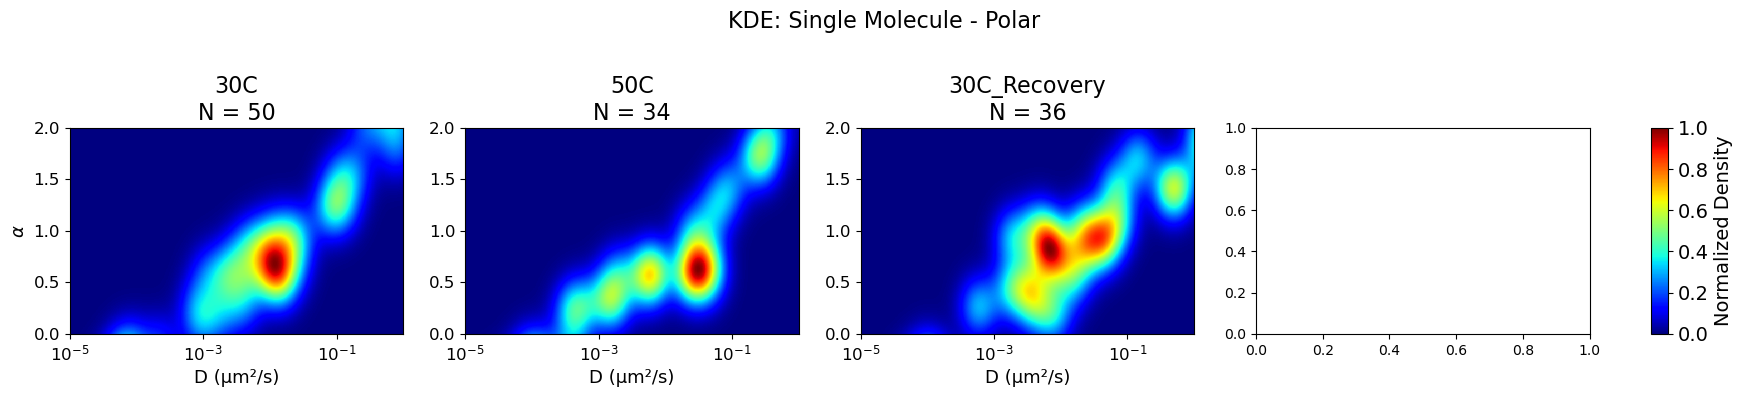

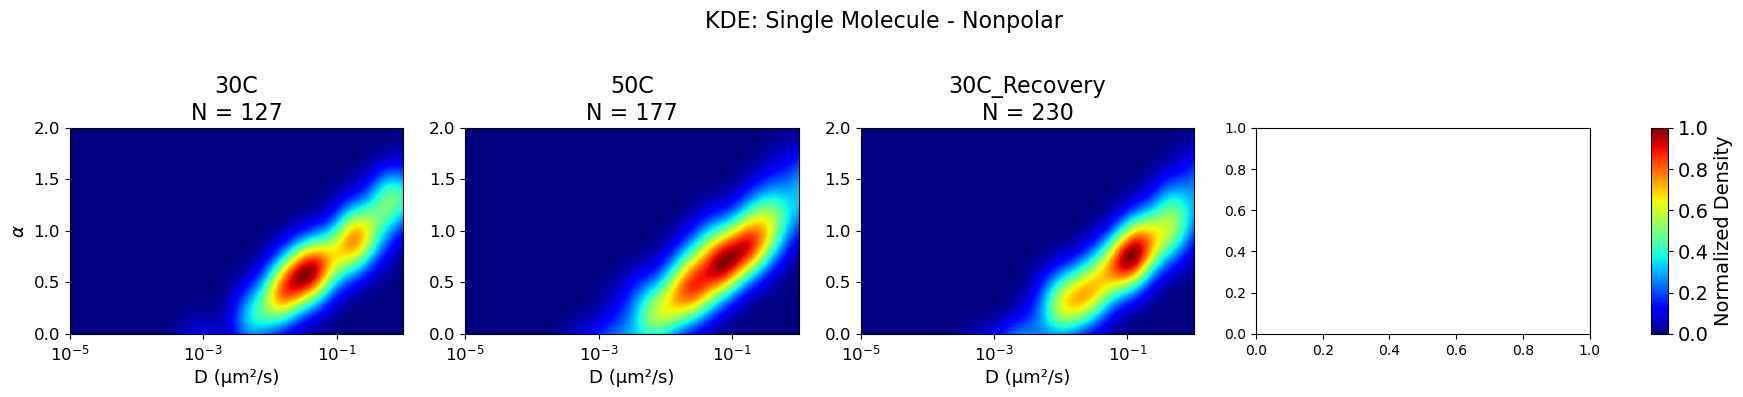

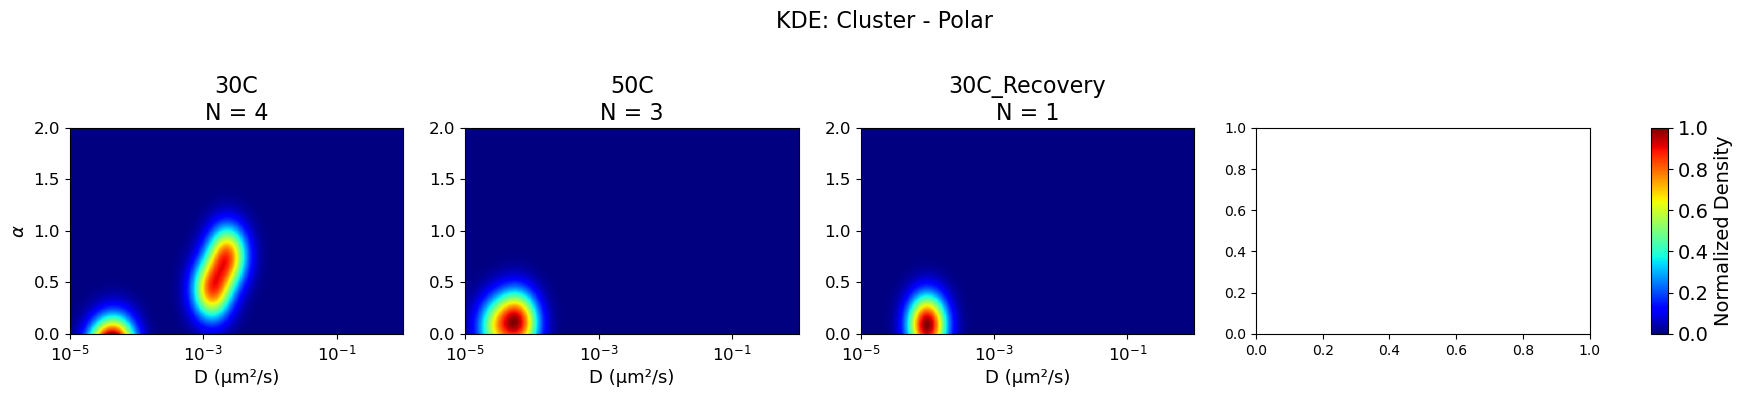

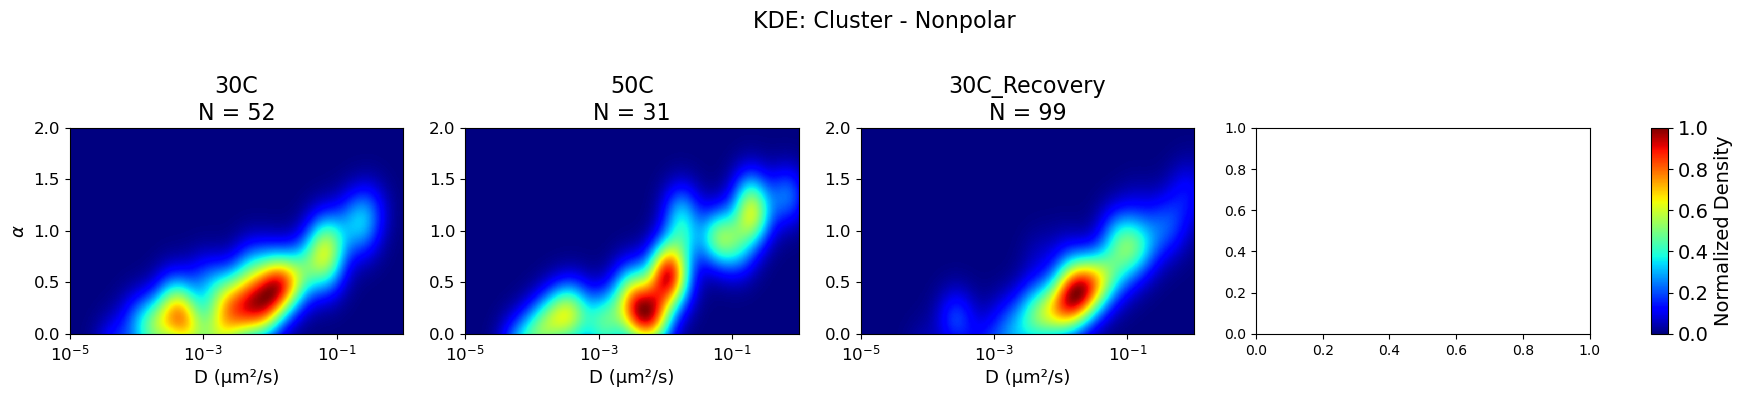

In [33]:
# Define KDE computation
def compute_2D_KDE(data_x, data_y, grid_x, grid_y, bandwidth):
    kde = KernelDensity(kernel='gaussian', bandwidth=bandwidth)
    points = np.vstack([data_x, data_y]).T
    kde.fit(points)
    grid_coords = np.vstack([grid_x.ravel(), grid_y.ravel()]).T
    log_density = kde.score_samples(grid_coords)
    density = np.exp(log_density).reshape(grid_x.shape)
    density /= density.max()
    return density

# Plot KDE heatmaps for different polarities and categories
def plot_kde_heatmaps_from_csv(df, bandwidth=0.2):
    D_min, D_max = 1e-5, 1
    alpha_min, alpha_max = 0, 2

    classifications = [
        ('single molecule', 'polar'),
        ('single molecule', 'nonpolar'),
        ('cluster', 'polar'),
        ('cluster', 'nonpolar')
    ]

    ordered_categories = ["30C_AfterActivation", "50C_AfterActivation", "30C_Recovery_AfterActivation"]

    for classification, polarity in classifications:
        fig = plt.figure(figsize=(18, 4))
        spec = gridspec.GridSpec(nrows=1, ncols=5, width_ratios=[1, 1, 1, 1, 0.05])
        axes = [fig.add_subplot(spec[0, i]) for i in range(4)]
        cax = fig.add_subplot(spec[0, 4])  # colorbar axis

        for i, category in enumerate(ordered_categories):
            subset = df[
                (df['Classification'] == classification) &
                (df['SM Polarity'].fillna('') == (polarity if classification == 'single molecule' else '')) &
                (df['Cluster Mobility'].fillna('') == (polarity if classification == 'cluster' else '')) &
                (df['Category'] == category)
            ].dropna(subset=['Diffusion Coefficient', 'Alpha'])
            
            # ... inside your loop for i, category in enumerate(ordered_categories):
            ax = axes[i]
            if subset.empty:
                ax.set_title(f"{category}\nNo Data")
                ax.axis('off')
                continue

            D = np.log10(subset['Diffusion Coefficient'].astype(float).values)
            alpha = subset['Alpha'].astype(float).values

            # Generate KDE
            D_grid = np.logspace(np.log10(D_min), np.log10(D_max), 600)
            alpha_grid = np.linspace(alpha_min, alpha_max, 600)
            grid_x, grid_y = np.meshgrid(D_grid, alpha_grid)
            density = compute_2D_KDE(D, alpha, np.log10(grid_x), grid_y, bandwidth)

            pcm = ax.pcolormesh(grid_x, grid_y, density, shading='auto',
                                cmap=plt.cm.jet, norm=Normalize(vmin=0, vmax=1))

            # Add category and track count
            clean_title = category.replace("_AfterActivation", "").replace("AfterActivation", "")
            N = len(subset)
            ax.set_title(f"{clean_title}\nN = {N}", fontsize=16)

            ax.set_xlabel('D (μm²/s)', fontsize=13)
            if i == 0:
                ax.set_ylabel(r'$\alpha$', fontsize=13)
            ax.tick_params(axis='both', labelsize=12)
            ax.set_xscale('log')
            ax.set_xlim(D_min, D_max)
            ax.set_ylim(alpha_min, alpha_max)

#             ax = axes[i]
#             if subset.empty:
#                 ax.set_title(f"{category}\nNo Data")
#                 ax.axis('off')
#                 continue

#             D = np.log10(subset['Diffusion Coefficient'].astype(float).values)
#             alpha = subset['Alpha'].astype(float).values

#             D_grid = np.logspace(np.log10(D_min), np.log10(D_max), 600)
#             alpha_grid = np.linspace(alpha_min, alpha_max, 600)
#             grid_x, grid_y = np.meshgrid(D_grid, alpha_grid)

#             density = compute_2D_KDE(D, alpha, np.log10(grid_x), grid_y, bandwidth)

#             pcm = ax.pcolormesh(grid_x, grid_y, density, shading='auto',
#                                 cmap=plt.cm.jet, norm=Normalize(vmin=0, vmax=1))
            
#             clean_title = category.replace("_AfterActivation", "").replace("AfterActivation", "")
#             ax.set_title(clean_title, fontsize=16)

#             #ax.set_title(category, fontsize=14)  # Title font size
#             ax.set_xlabel('D (μm²/s)', fontsize=13)  # X-axis label font
#             if i == 0:
#                 ax.set_ylabel(r'$\alpha$', fontsize=13)  # Y-axis label font only for first plot

#             # Tick label font size
#             ax.tick_params(axis='both', labelsize=12)

            
#             ax.set_xscale('log')
#             ax.set_xlim(D_min, D_max)
#             ax.set_ylim(alpha_min, alpha_max)

#             ax.set_title(category)
#             ax.set_xlabel('D (μm²/s)')
#             if i == 0:
#                 ax.set_ylabel(r'$\alpha$')
        fig.suptitle(f"KDE: {classification.title()} - {polarity.title()}", fontsize=16)
#         fig.colorbar(pcm, cax=cax, label='Normalized Density').ax.tick_params(labelsize=16)
        cbar = fig.colorbar(pcm, cax=cax)
        cbar.set_label('Normalized Density', fontsize=14)  # <-- change 12 to any size you want
        cbar.ax.tick_params(labelsize=14)  # Optional: adjust tick font size too


#         fig.suptitle(f"KDE: {classification.title()} - {polarity.title()}", fontsize=14)
#         fig.colorbar(pcm, cax=cax, label='Normalized Density')
        plt.tight_layout(rect=[0, 0, 0.98, 0.95])
        plt.show()

# Execute KDE plotting
plot_kde_heatmaps_from_csv(mobility_df, bandwidth=0.2)

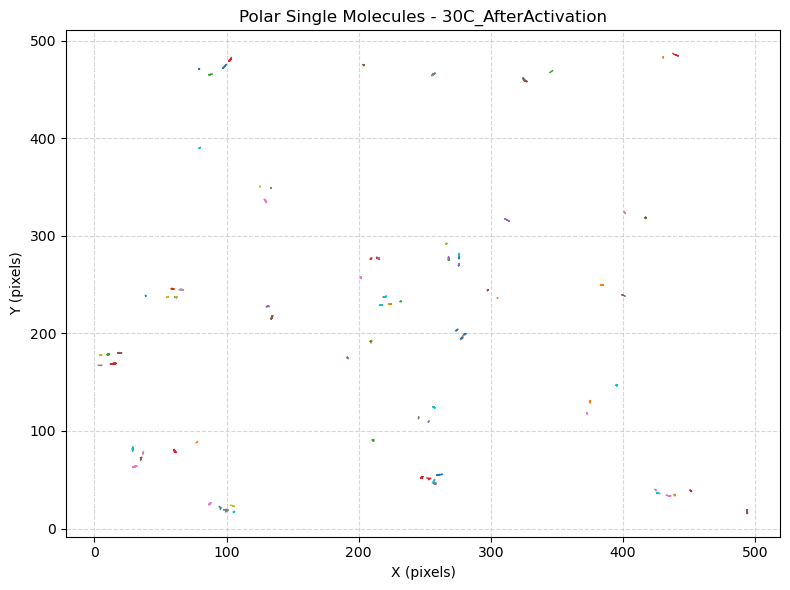

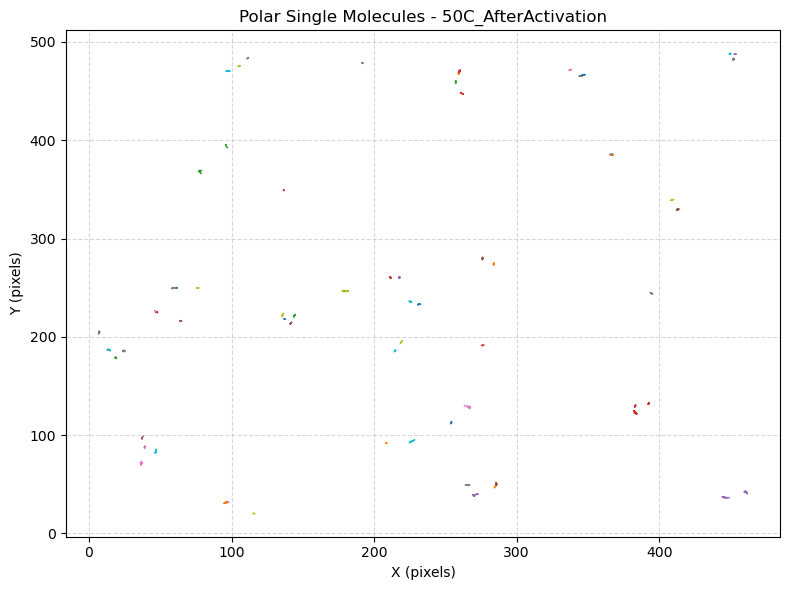

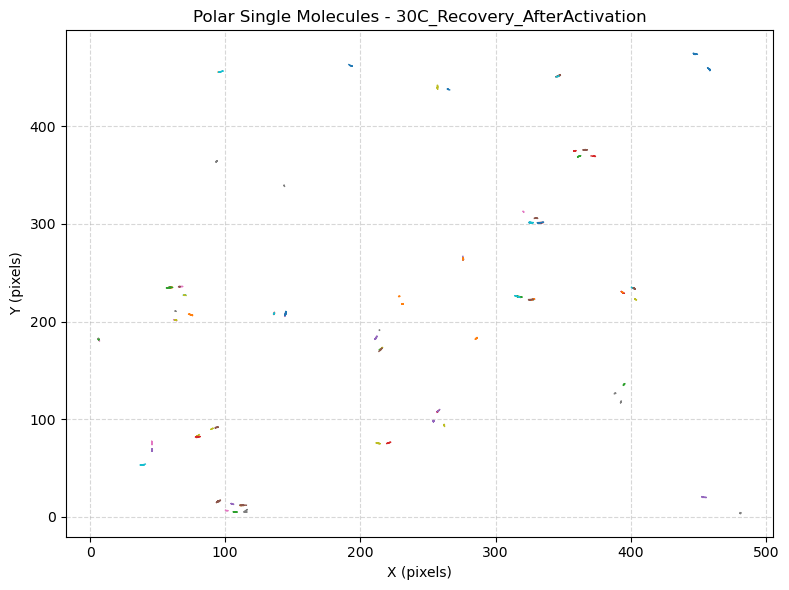

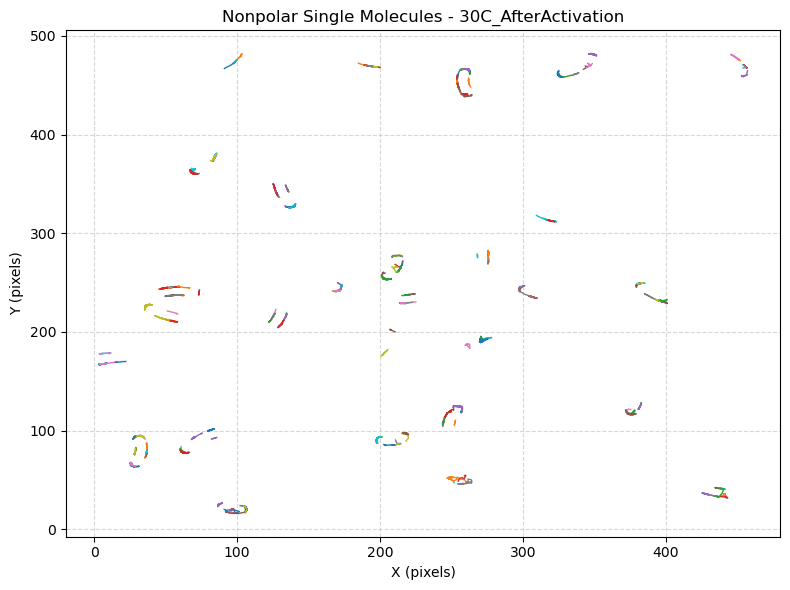

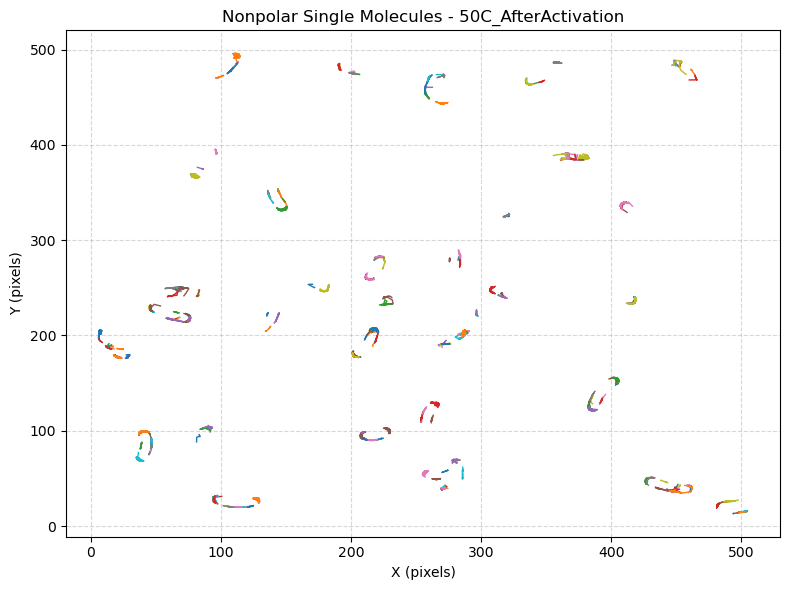

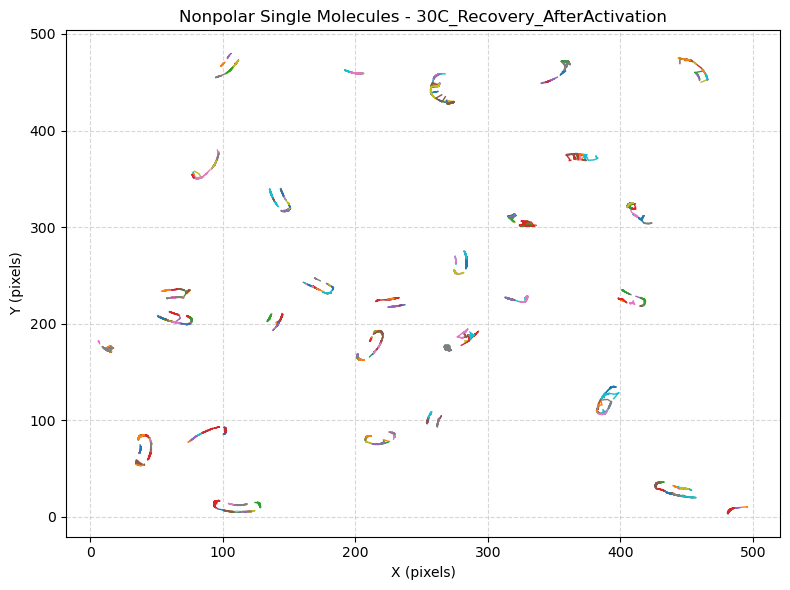

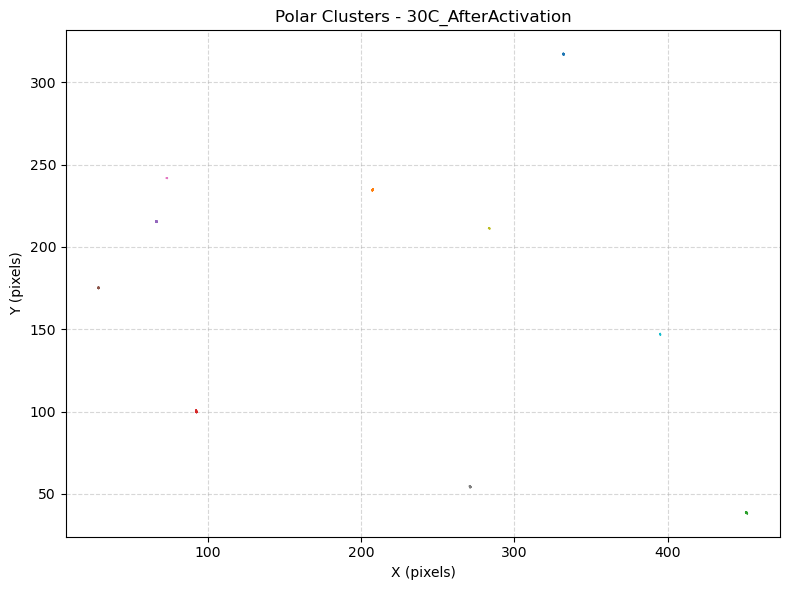

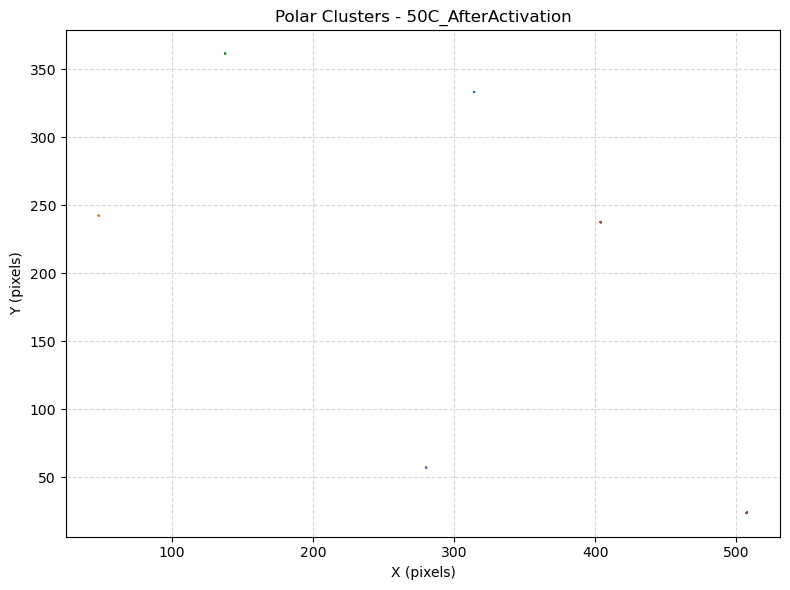

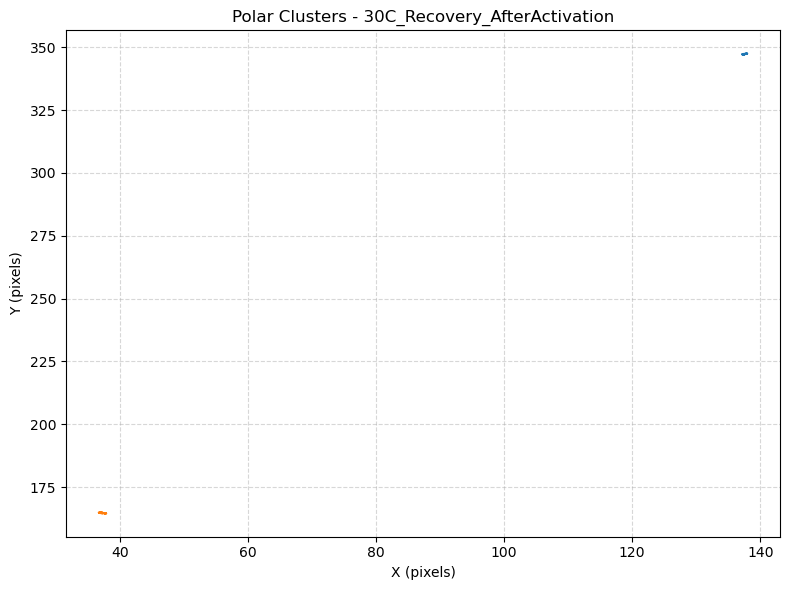

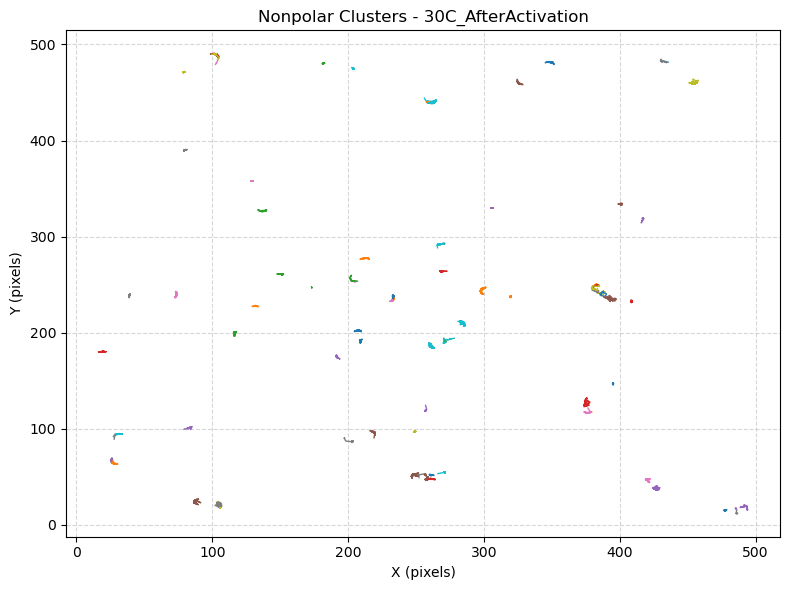

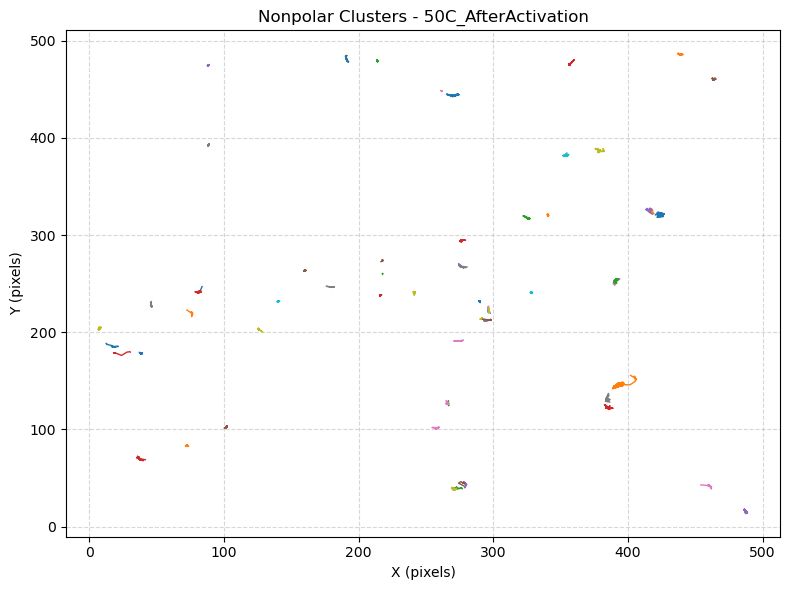

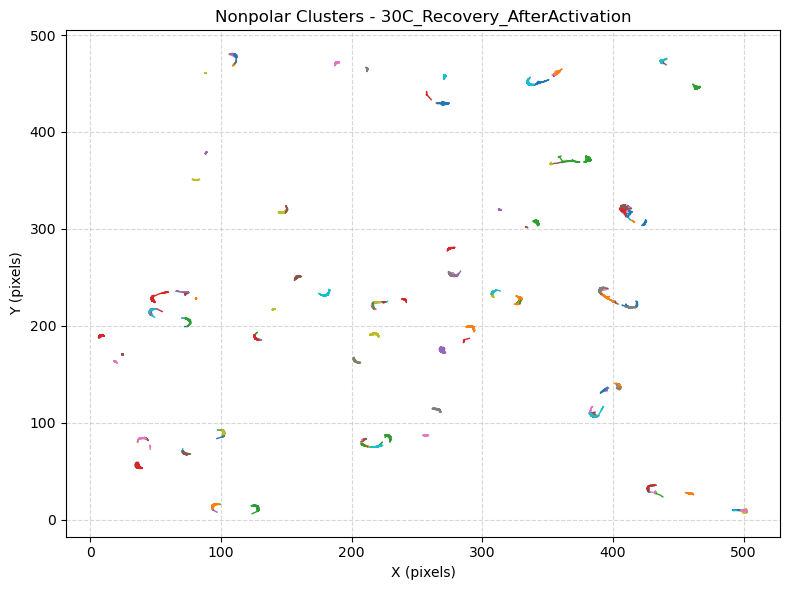

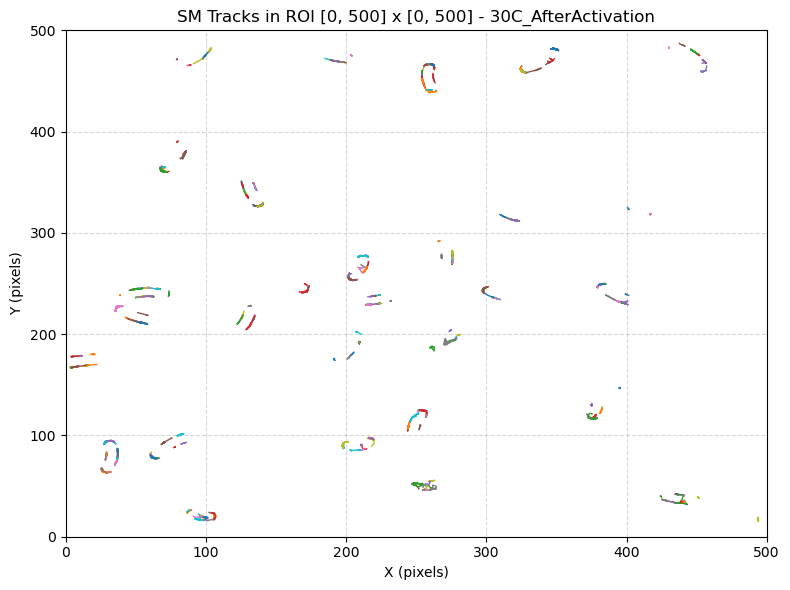

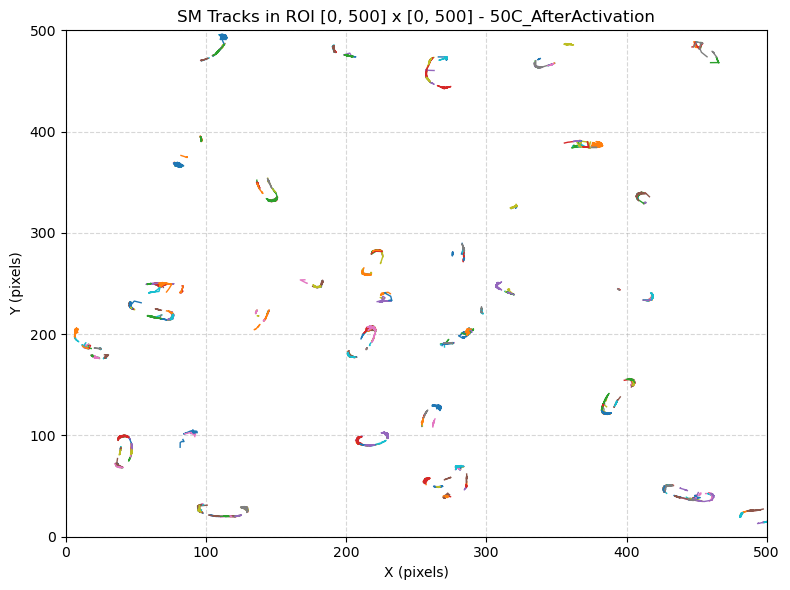

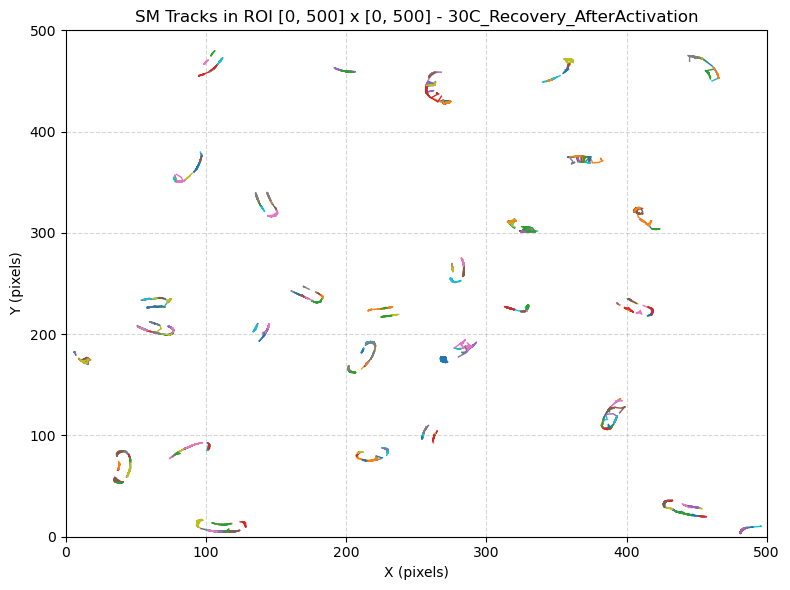

In [34]:
# Reload mobility and input file
mobility_df = pd.read_csv("Particle_Mobility_Analysis.csv")
input_df = pd.read_csv("input_files.csv")

# Reconstruct grouped_data
grouped_data = {}
file_lookup = {}

for _, row in input_df.iterrows():
    category = row['category']
    filepath = row['filepath']
    full_path = f"{filepath}"
    if category not in grouped_data:
        grouped_data[category] = []
    try:
        df = pd.read_csv(full_path)
        df.attrs['filepath'] = full_path
        grouped_data[category].append(df)
        file_lookup[os.path.basename(full_path)] = df
    except Exception as e:
        print(f"❌ Failed to load {filepath}: {e}")

# Define subsets
sm_polar = mobility_df[(mobility_df["Classification"] == "single molecule") & (mobility_df["SM Polarity"] == "polar")]
sm_nonpolar = mobility_df[(mobility_df["Classification"] == "single molecule") & (mobility_df["SM Polarity"] == "nonpolar")]
cluster_polar = mobility_df[(mobility_df["Classification"] == "cluster") & (mobility_df["Cluster Mobility"] == "polar")]
cluster_nonpolar = mobility_df[(mobility_df["Classification"] == "cluster") & (mobility_df["Cluster Mobility"] == "nonpolar")]

# Function to plot trajectories by category
def plot_trajectories_by_category(particle_df, title_prefix):
    for category in particle_df['Category'].unique():
        subset = particle_df[particle_df['Category'] == category]
        plt.figure(figsize=(8, 6))
        for _, row in subset.iterrows():
            file_name = os.path.basename(row["File Name"])
            particle_id = row["Particle ID"]

            if file_name not in file_lookup:
                continue

            df = file_lookup[file_name]
            traj = df[df["particle"] == particle_id].sort_values("frame")

            if {"x", "y"}.issubset(traj.columns) and not traj.empty:
                plt.plot(traj["x"], traj["y"], linewidth=1)

        plt.xlabel("X (pixels)")
        plt.ylabel("Y (pixels)")
        plt.title(f"{title_prefix} - {category}")
        plt.grid(True, linestyle='--', alpha=0.5)
        plt.tight_layout()
        plt.show()


def plot_selected_single_molecules(mobility_df, file_lookup, x_range, y_range):
    # Filter for single molecules
    sm_df = mobility_df[mobility_df["Classification"] == "single molecule"]

    found_any = False

    for category in sm_df['Category'].unique():
        category_subset = sm_df[sm_df['Category'] == category]
        plt.figure(figsize=(8, 6))
        plotted = False

        for _, row in category_subset.iterrows():
            file_name = os.path.basename(row["File Name"])
            particle_id = row["Particle ID"]

            if file_name not in file_lookup:
                continue

            traj_df = file_lookup[file_name]
            traj = traj_df[traj_df["particle"] == particle_id]

            # Check if any point in the trajectory is within the desired region
            if not traj.empty and {"x", "y"}.issubset(traj.columns):
                in_region = ((traj["x"] >= x_range[0]) & (traj["x"] <= x_range[1]) &
                             (traj["y"] >= y_range[0]) & (traj["y"] <= y_range[1]))

                if in_region.any():
                    plt.plot(traj["x"], traj["y"], linewidth=1)
                    plotted = True
                    found_any = True

        if plotted:
            plt.xlabel("X (pixels)")
            plt.ylabel("Y (pixels)")
            plt.title(f"SM Tracks in ROI [{x_range[0]}, {x_range[1]}] x [{y_range[0]}, {y_range[1]}] - {category}")
            plt.xlim(x_range)  # <- Force same x-axis range
            plt.ylim(y_range)  # <- Force same y-axis range
            plt.grid(True, linestyle='--', alpha=0.5)
            plt.tight_layout()
            plt.show()

    if not found_any:
        print("⚠️ No single molecule trajectories passed through the specified region.")



        
# Plot by category
plot_trajectories_by_category(sm_polar, "Polar Single Molecules")
plot_trajectories_by_category(sm_nonpolar, "Nonpolar Single Molecules")
plot_trajectories_by_category(cluster_polar, "Polar Clusters")
plot_trajectories_by_category(cluster_nonpolar, "Nonpolar Clusters")
plot_selected_single_molecules(
    mobility_df, 
    file_lookup, 
    x_range=(0, 500), 
    y_range=(0, 500)
)



In [35]:
# # Constants
# fps = 100
# mass_change_threshold = 200  # Mass delta threshold for detecting binding/unbinding

# # Initialize list to collect all rows
# poisson_records = []

# # Process each group
# for group_name, dfs in grouped_data.items():
#     if not dfs:
#         continue

#     particle_offset = 0
#     adjusted_dfs = []

#     for df in dfs:
#         if not all(col in df.columns for col in ['frame', 'mass', 'particle', 'classification']):
#             continue
#         df = df.copy()
#         df['particle'] += particle_offset
#         particle_offset = df['particle'].max() + 1
#         adjusted_dfs.append(df)

#     if not adjusted_dfs:
#         continue

#     combined_df = pd.concat(adjusted_dfs, ignore_index=True)
#     combined_df = combined_df.dropna(subset=['mass'])

#     # ➤ Only keep cluster trajectories
#     cluster_df = combined_df[combined_df['classification'].str.lower() == 'cluster'].copy()
#     if cluster_df.empty:
#         continue

#     frame_data = []

#     for particle_id, traj in cluster_df.groupby('particle'):
#         traj_sorted = traj.sort_values('frame')
#         masses = traj_sorted['mass'].values
#         frames = traj_sorted['frame'].values

#         delta_mass = np.diff(masses)
#         delta_frames = frames[1:]

#         for i, delta in enumerate(delta_mass):
#             if delta > mass_change_threshold:
#                 frame_data.append((delta_frames[i], 'bind'))
#             elif delta < -mass_change_threshold:
#                 frame_data.append((delta_frames[i], 'unbind'))

#     if not frame_data:
#         continue

#     # Convert event data to DataFrame
#     frame_df = pd.DataFrame(frame_data, columns=['frame', 'event'])

#     # Per-frame summary
#     summary = frame_df.groupby(['frame', 'event']).size().unstack(fill_value=0).reset_index()
#     summary['temperature'] = group_name

#     # Rates and Poisson standard deviations
#     summary['binding_rate'] = summary.get('bind', 0) / fps
#     summary['unbinding_rate'] = summary.get('unbind', 0) / fps
#     summary['std_binding_rate'] = np.sqrt(summary.get('bind', 0)) / fps
#     summary['std_unbinding_rate'] = np.sqrt(summary.get('unbind', 0)) / fps

#     poisson_records.append(summary[['temperature', 'frame', 'bind', 'unbind',
#                                     'binding_rate', 'unbinding_rate',
#                                     'std_binding_rate', 'std_unbinding_rate']])

# # Combine all into one DataFrame
# if poisson_records:
#     poisson_df = pd.concat(poisson_records, ignore_index=True)
#     poisson_df.columns = ['Temperature', 'Frame', 'Binds', 'Unbinds',
#                           'Binding Rate', 'Unbinding Rate',
#                           'Std Binding Rate', 'Std Unbinding Rate']

#     # Save to CSV
#     csv_path = "Poisson_Statistic.csv"
#     poisson_df.to_csv(csv_path, index=False)
#     print(f"✅ Saved Poisson statistics to: {csv_path}")

#     # Create summary
#     summary_df = poisson_df.groupby("Temperature").agg({
#         "Binds": "sum",
#         "Unbinds": "sum",
#         "Binding Rate": "mean",
#         "Unbinding Rate": "mean",
#         "Std Binding Rate": "mean",
#         "Std Unbinding Rate": "mean",
#         "Frame": "count"
#     }).reset_index()

#     summary_df["Total Transitions"] = summary_df["Binds"] + summary_df["Unbinds"]
#     summary_df.rename(columns={"Frame": "Frame Count"}, inplace=True)

#     print("\n📊 Binding/Unbinding Summary by Temperature:")
#     print(summary_df)

# else:
#     print("⚠️ No valid binding/unbinding events detected based on the current threshold and data.")

In [36]:
# # Constants
# fps = 100
# mass_change_threshold = 200  # Mass difference to define transition

# poisson_summary = []

# for group_name, dfs in grouped_data.items():
#     if not dfs:
#         continue

#     particle_offset = 0
#     adjusted_dfs = []

#     for df in dfs:
#         if not all(col in df.columns for col in ['frame', 'mass', 'particle', 'classification']):
#             continue
#         df = df.copy()
#         df['particle'] += particle_offset
#         particle_offset = df['particle'].max() + 1
#         adjusted_dfs.append(df)

#     if not adjusted_dfs:
#         continue

#     combined_df = pd.concat(adjusted_dfs, ignore_index=True)
#     combined_df = combined_df.dropna(subset=['mass'])

#     # ▶ Filter to cluster only
#     cluster_df = combined_df[combined_df['classification'].str.lower() == 'cluster'].copy()
#     if cluster_df.empty:
#         continue

#     bind_durations = []
#     unbind_durations = []

#     for _, traj in cluster_df.groupby('particle'):
#         traj_sorted = traj.sort_values('frame')
#         masses = traj_sorted['mass'].values
#         frames = traj_sorted['frame'].values

#         state = masses[0] > masses[1]  # Just initialize with False or True
#         last_transition_frame = frames[0]

#         for i in range(1, len(frames)):
#             delta_mass = masses[i] - masses[i - 1]
#             frame_now = frames[i]

#             # Detect binding (mass increased)
#             if delta_mass > mass_change_threshold:
#                 duration = (frame_now - last_transition_frame) / fps
#                 unbind_durations.append(duration)  # Since we were unbound until now
#                 last_transition_frame = frame_now
#                 state = True  # now bound

#             # Detect unbinding (mass decreased)
#             elif delta_mass < -mass_change_threshold:
#                 duration = (frame_now - last_transition_frame) / fps
#                 bind_durations.append(duration)  # Since we were bound until now
#                 last_transition_frame = frame_now
#                 state = False  # now unbound

#     # Calculate means and stds
#     if bind_durations:
#         mean_bind_rate = 1 / np.mean(bind_durations)
#         std_bind_time = np.std(bind_durations)
#     else:
#         mean_bind_rate = 0
#         std_bind_time = 0

#     if unbind_durations:
#         mean_unbind_rate = 1 / np.mean(unbind_durations)
#         std_unbind_time = np.std(unbind_durations)
#     else:
#         mean_unbind_rate = 0
#         std_unbind_time = 0

#     poisson_summary.append({
#         'Temperature': group_name,
#         'Bind Events': len(bind_durations),
#         'Unbind Events': len(unbind_durations),
#         'Mean Bind Time (s)': np.mean(bind_durations) if bind_durations else np.nan,
#         'Mean Unbind Time (s)': np.mean(unbind_durations) if unbind_durations else np.nan,
#         'Binding Rate (1/s)': mean_bind_rate,
#         'Unbinding Rate (1/s)': mean_unbind_rate,
#         'Std Bind Time (s)': std_bind_time,
#         'Std Unbind Time (s)': std_unbind_time
#     })

# # Convert to DataFrame
# poisson_rate_df = pd.DataFrame(poisson_summary)
# print(poisson_rate_df)
